# Avance 5 · Modelo final
## Avocado Insights | Ensambles, validación temporal y decisión de negocio

**Equipo 4 · TC5035.10 · 1 de noviembre de 2026**  
**Profesor:** Dr. Raúl Valente Ramírez Velarde  
**Sponsor:** Dr. Jorge Antonio Ascencio Gutiérrez

| Integrante | Matrícula |
|---|---|
| José Roberto Sánchez Rocha | A00903762 |
| Josué Águila Ramos | A01796400 |
| Roberto Perézcano Hernández | A01730502 |

**Objetivo.** Determinar si combinar predictores mejora la estimación de producción anual
municipal de aguacate, en toneladas, con un costo y una complejidad justificables.

Se construyen **siete ensambles**: cuatro homogéneos y tres heterogéneos. Se comparan con los
siete algoritmos individuales de la fase anterior, Ridge A3 y persistencia. Los dos mejores
individuales del Avance 4 —Huber y regresión cuantílica ajustados— constituyen las bases de
voting, stacking y blending. Se optimizan tres ensambles relevantes, se congela la elección
antes de puntuar las pruebas retrospectivas y se entrega un predictor serializado reproducible.

| Rúbrica | Evidencia |
|---|---|
| Ensambles · 60 puntos | Siete modelos; bagging, bosques y boosting homogéneos; voting, stacking y blending heterogéneos con Huber/Cuantil A4; optimización registrada |
| Selección · 20 puntos | Tablas ordenadas por MAE, individuales previos y referencias, RMSE, WAPE, R², RMSLE, sesgo y tiempos; decisión temporal y de complejidad |
| Gráficos · 20 puntos | Cuatro figuras principales del rendimiento final, cada una con interpretación calculada; tendencia, diversidad, incertidumbre y estados adicionales |
| Declaración obligatoria | Última celda de texto; tablas de IA y contribuciones idénticas a la versión final del Avance 4 |

El alcance sigue siendo producción agrícola. Las fuentes no miden ventas, rutas, emisiones
o costos logísticos. La aceptación operativa y los costos de sobre/subestimación permanecen
pendientes de validación con el sponsor.

In [1]:
from pathlib import Path
import sys,json,hashlib,time,platform,joblib
import numpy as np,pandas as pd,scipy,sklearn,matplotlib,pdfplumber,seaborn as sns
import matplotlib.pyplot as plt
from IPython.display import display,Markdown
ROOT=next((p for p in [Path.cwd(),*Path.cwd().parents] if (p/'src/ensambles_avance5.py').exists()),None)
if ROOT is None:raise FileNotFoundError('Se necesita la estructura completa del proyecto: src/, data/ y documentacion/.')
sys.path.insert(0,str(ROOT/'src'))
from ensambles_avance5 import (ENSEMBLES,HOMOGENEOUS,HETEROGENEOUS,INITIAL,ALGORITHMS,FEATURE_SETS,
    COMPLEXITY,load_frame,base_configs,evaluate,choose_relevant,parameter_space,tune,select_final,
    build,strategy,canonical,config_id,metrics,state_bootstrap)
from baseline_avance3 import verify_external_files,STATE_NAMES
from fe_avance2 import RAW_SHA256
OUT=ROOT/'resultados/avance5';DATA=ROOT/'data/avance5';DOC=ROOT/'documentacion/avance5';SEARCH=OUT/'busquedas'
for p in [OUT,DATA,DOC,SEARCH]:p.mkdir(parents=True,exist_ok=True)
protocol=json.loads((DOC/'protocolo_evaluacion.json').read_text())
protocol_sha=hashlib.sha256((DOC/'protocolo_evaluacion.json').read_bytes()).hexdigest()
continuity=json.loads((DOC/'continuidad.json').read_text())
previous=base_configs(ROOT)
previous_manifest=json.loads((ROOT/'documentacion/avance4/base_repositorio.json').read_text())
versions={'python':platform.python_version(),'numpy':np.__version__,'pandas':pd.__version__,
 'scipy':scipy.__version__,'scikit-learn':sklearn.__version__,'matplotlib':matplotlib.__version__,
 'seaborn':sns.__version__,'joblib':joblib.__version__,'pdfplumber':pdfplumber.__version__}
sns.set_theme(style='whitegrid',palette=['#1D7657','#D5A23D','#407797','#9A70A8'])
plt.rcParams.update({'figure.dpi':115,'savefig.dpi':155,'axes.spines.top':False,'axes.spines.right':False,
 'axes.titleweight':'bold','text.color':'#213E32','axes.labelcolor':'#213E32'})
pd.set_option('display.max_rows',85);pd.set_option('display.max_columns',20);pd.set_option('display.max_colwidth',None)
pd.set_option('display.float_format',lambda x:f'{x:,.4f}')
def table(d,name):d.to_csv(OUT/(name+'.csv'),index=False);display(d)
def figsave(name):plt.tight_layout();plt.savefig(OUT/(name+'.png'),bbox_inches='tight');plt.show()
print('Entorno:',json.dumps(versions,ensure_ascii=False))
print('Configuraciones A4 preservadas:',canonical(previous))
print('Semillas fijas; n_jobs=1 y early_stopping=False; ejecución temporal sin mezcla aleatoria de años.')

Entorno: {"python": "3.12.14", "numpy": "2.3.5", "pandas": "2.2.3", "scipy": "1.17.0", "scikit-learn": "1.8.0", "matplotlib": "3.10.8", "seaborn": "0.13.2", "joblib": "1.5.3", "pdfplumber": "0.11.9"}
Configuraciones A4 preservadas: {"Cuantil":{"alpha":0.0,"features":"completo"},"Huber":{"alpha":1.2649989970392911e-06,"epsilon":1.01,"features":"completo"}}
Semillas fijas; n_jobs=1 y early_stopping=False; ejecución temporal sin mezcla aleatoria de años.


### 1. Continuidad, población y contrato temporal

Se reutiliza la instantánea de datos y los módulos del Avance 4 sin modificar sus bytes.
Producción, áreas, rendimiento y memoria histórica se integran con inflación de Estados Unidos,
tipo de cambio de México y temperatura estatal. Las 17 entradas son las mismas de la comparación
anterior. Los subconjuntos `capacidad` y `completo` pueden explorarse en los ensambles que lo permiten.

La historia estatal 1980–2002 no se convierte artificialmente en municipios. Agricultura 2024
permanece en cuarentena por claves ambiguas. El PDF climático nominal 2013 muestra 2012 y no se
integra ni se reasigna. Un cero observado permanece; no se imputa el objetivo de un municipio
ausente. Las ausencias de X se tratan dentro del ajuste, con mediana e indicadores.

**Escenario:** mediciones hasta t−2 y etiquetas de entrenamiento hasta t−3. Las variables se
reconstruyen desde los archivos originales incluidos. Las fuentes son instantáneas revisadas;
no existe un archivo completo de su disponibilidad histórica (Equipo 4, 2026).

| Etapa | Años objetivo | Uso permitido |
|---|---|---|
| Desarrollo y optimización | 2018–2020 | Comparar, seleccionar tres ensambles relevantes y ajustar sus parámetros |
| Confirmación | 2021–2022 | Elegir una configuración final, con reglas congeladas |
| Evaluación retrospectiva reutilizada | 2023 y 2025 | Puntuar modelos congelados y diagnosticar errores; no reabrir selección |

**Límite de independencia.** 2023 se evaluó en A3 y 2025 en A4. Además, las configuraciones
individuales se heredaron de búsquedas anteriores. Por ello no se presenta ninguno como un
nuevo test ciego. Cada predicción se obtiene con etiquetas excluidas de su ajuste, pero el proceso
completo de desarrollo ya conoce esos periodos. Una validación prospectiva nueva queda pendiente.

MAE en toneladas por municipio-año sigue siendo la métrica principal, bajo costos simétricos
provisionales. RMSE expone errores grandes, WAPE contextualiza volumen, sesgo da dirección, y
R²/RMSLE complementan el análisis. No se usa MAPE ante ceros. Las métricas concatenan observaciones
de los años de cada etapa; la dependencia estatal y temporal impide tratarlas como réplicas
independientes. La preparación se aprende solo en entrenamiento (The scikit-learn developers,
s. f.-b, s. f.-c, s. f.-g).

,conjunto,filas,tratamiento
0,Fuente agrícola,15474,Original preservado
1,Historia estatal,981,"Separada, 1980–2002"
2,Cuarentena agrícola 2024,900,No se utiliza
3,Panel compatible,11665,Municipio-año
4,Filas modelables,9247,y observado e historia t−2
5,Clima aceptado,660,20 años; 2013 aislado


,modelo,configuracion_A4
0,Cuantil,"{""alpha"":0.0,""features"":""completo""}"
1,Huber,"{""alpha"":1.2649989970392911e-06,""epsilon"":1.01,""features"":""completo""}"


,fase,anio,fin_train,n_train,n_evaluacion,cobertura_municipal_pct,cobertura_volumen_pct
0,Desarrollo,2018,2015,3930,558,92.0792,99.7963
1,Desarrollo,2019,2016,4444,578,92.0382,99.8365
2,Desarrollo,2020,2017,4973,598,94.1732,99.8456
3,Confirmación,2021,2018,5531,622,97.4922,99.9856
4,Confirmación,2022,2019,6109,634,98.6003,99.9495
5,Prueba reutilizada,2023,2020,6707,637,98.3025,99.9416
6,Prueba reutilizada,2025,2022,7963,647,98.7786,99.8963


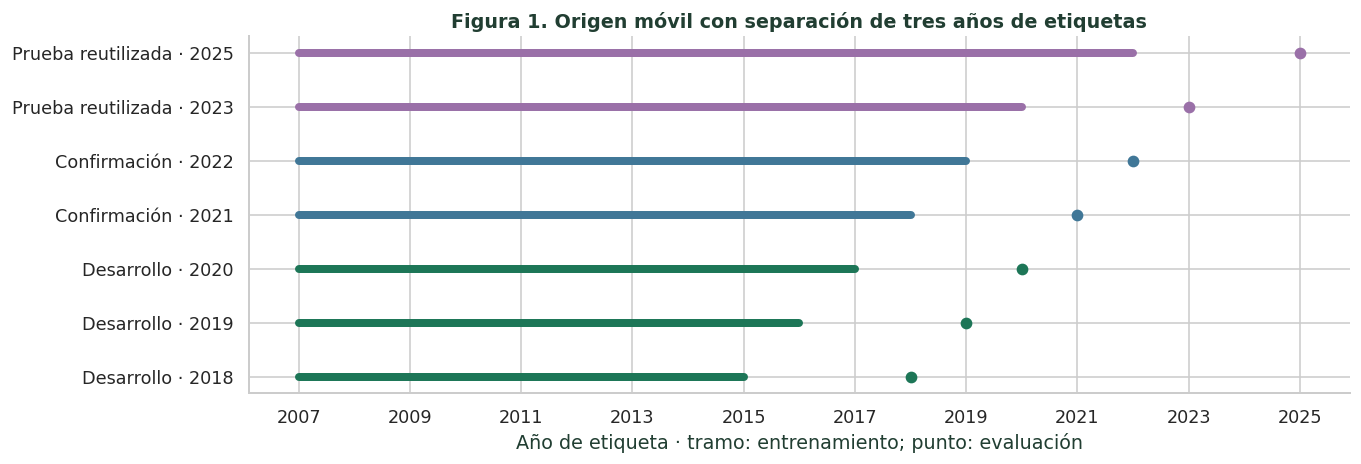

In [2]:
raw,panel,frame,temperature,macro,history,quarantine=load_frame(ROOT)
temperature.attrs['auditoria'] and pd.DataFrame(temperature.attrs['auditoria']).to_csv(DATA/'auditoria_smn.csv',index=False)
quality=pd.DataFrame([
 ['Fuente agrícola',len(raw),'Original preservado'],['Historia estatal',len(history),'Separada, 1980–2002'],
 ['Cuarentena agrícola 2024',len(quarantine),'No se utiliza'],['Panel compatible',len(panel),'Municipio-año'],
 ['Filas modelables',len(frame),'y observado e historia t−2'],['Clima aceptado',len(temperature),'20 años; 2013 aislado']
],columns=['conjunto','filas','tratamiento'])
table(quality,'01_continuidad_datos')
table(pd.DataFrame([{'modelo':k,'configuracion_A4':canonical(v)} for k,v in previous.items()]),'02_bases_heredadas')
windows=[]
for phase,years in [('Desarrollo',[2018,2019,2020]),('Confirmación',[2021,2022]),('Prueba reutilizada',[2023,2025])]:
 for year in years:
    tr=frame.loc[frame.anio.between(2007,year-3)];te=frame.loc[frame.anio.eq(year)];all_y=panel.loc[panel.anio.eq(year)]
    windows.append({'fase':phase,'anio':year,'fin_train':year-3,'n_train':len(tr),'n_evaluacion':len(te),
      'cobertura_municipal_pct':100*len(te)/len(all_y),'cobertura_volumen_pct':100*te.produccion_t.sum()/all_y.produccion_t.sum()})
windows=pd.DataFrame(windows);table(windows,'03_ventanas_y_cobertura')
fig,ax=plt.subplots(figsize=(12,4.2))
colors={'Desarrollo':'#1D7657','Confirmación':'#407797','Prueba reutilizada':'#9A70A8'}
for j,r in windows.iterrows():
 ax.plot([2007,r.fin_train],[j,j],lw=5,color=colors[r.fase]);ax.scatter(r.anio,j,s=40,color=colors[r.fase])
ax.set(yticks=range(len(windows)),yticklabels=[f'{r.fase} · {r.anio}' for r in windows.itertuples()],
 xticks=range(2007,2026,2),xlabel='Año de etiqueta · tramo: entrenamiento; punto: evaluación',title='Figura 1. Origen móvil con separación de tres años de etiquetas')
figsave('fig01_diseno_temporal')

### 2. Arquitecturas de ensamble y prevención de fuga

| Ensamble | Estrategia | Construcción y justificación |
|---|---|---|
| Bagging Huber | Homogénea | Promedia regresores Huber de remuestras de entrenamiento; explora estabilidad frente a composición muestral |
| Random Forest | Homogénea | Árboles con bootstrap y selección de variables; permite interacciones con reducción de varianza |
| Extra Trees | Homogénea | Árboles con umbrales aleatorizados, sin bootstrap en esta especificación; otra fuente de diversidad |
| HistGradientBoosting | Homogénea | Suma secuencial de árboles con pérdida absoluta y sin parada aleatoria; representa patrones residuales |
| Voting H-Q | Heterogénea | Media ponderada de Huber y cuantílica ajustados en A4; ambos pesos se mantienen positivos |
| Stacking temporal | Heterogénea | Metamodelo Ridge positivo o Huber sobre predicciones temporales fuera de muestra de Huber/Cuantil A4 |
| Blending temporal | Heterogénea | Metamodelo sobre años de calibración posteriores al ajuste de Huber/Cuantil; conserva las bases sin reajuste |

Los heterogéneos combinan `HuberRegressor` y `QuantileRegressor`, dos estimadores con pérdidas y procedimientos de ajuste distintos. Ambos tienen forma lineal; la heterogeneidad algorítmica es limitada y no implica diversidad suficiente de errores. La figura 3 mide esa limitación.

Se usan las implementaciones oficiales para bagging, bosques y boosting. Voting y los dos
metamodelos se implementan explícitamente para respetar las filas y los cortes temporales del
panel; no se afirma haber utilizado `StackingRegressor` con su validación predeterminada
(The scikit-learn developers, s. f.-a, s. f.-d, s. f.-e, s. f.-f, s. f.-h, s. f.-i, s. f.-j).

**Stacking.** Para una etiqueta interna s, las bases se ajustan solo con etiquetas ≤s−3.
Sus predicciones se concatenan como datos OOF del metamodelo. Este aprende sus escalas únicamente
en esas filas. Después se reajustan las bases con toda la historia permitida en el origen externo.
Se evita entrenar el metamodelo con predicciones ajustadas sobre sus mismas etiquetas.

**Blending.** Se reservan el último año o los dos últimos años del entrenamiento externo para
calibración. Las bases se ajustan hasta el primer año de calibración menos tres y se mantienen
en ese estado al evaluar el origen externo. Esto utiliza menos historia para las bases y puede
costar precisión; no se oculta cambiando a un reajuste posterior que altere la distribución.

**Objetivo residual en árboles.** Algunas configuraciones predicen `produccion_t − produccion_lag2`
y suman después el nivel histórico disponible. Es una transformación supervisada dentro de
entrenamiento para permitir extrapolar escala mediante el nivel conocido, no una nueva variable
futura ni un resultado observado usado al predecir. La alternativa de nivel directo también se
explora si ese ensamble es seleccionado para ajuste.

En los modelos homogéneos se comparten imputación y escalas aprendidas en el entrenamiento externo;
las remuestras de bagging ocurren después de esa preparación. La estandarización lineal de y se
invierte a toneladas. El remuestreo de bagging no constituye validación temporal ni un intervalo
de incertidumbre. No se eliminan extremos válidos y las salidas finales negativas se limitan a cero.

In [3]:
individual_rows=[];individual_folds=[];individual_predictions=[]
for name in ALGORITHMS+['Ridge A3','Persistencia t-2']:
 s,d,p,a=evaluate(frame,name,None,previous,[2018,2019,2020],cache=False)
 individual_rows.append(s);individual_folds.append(d);individual_predictions.append(p)
 print(name,'MAE',round(s['MAE_t'],3),'convergente',s['convergencia'],flush=True)
individual_dev=pd.DataFrame(individual_rows)
table(individual_dev.sort_values('MAE_t'),'04_individuales_desarrollo')
pd.concat(individual_folds,ignore_index=True).to_csv(OUT/'05_individuales_por_ventana.csv',index=False)

ElasticNet MAE 561.293 convergente True
Huber MAE 455.182 convergente True
Cuantil MAE 455.514 convergente True
CART MAE 746.838 convergente True
KNN MAE 1015.938 convergente True
SVR MAE 1871.455 convergente True
MLP MAE 949.979 convergente True
Ridge A3 MAE 539.952 convergente True
Persistencia t-2 MAE 584.308 convergente True


,modelo,estrategia,n,MAE_t,RMSE_t,WAPE_pct,sesgo_t,sesgo_pct,R2,RMSLE,entrenamiento_s,entrenamiento_promedio_s,prediccion_s,convergencia,cache
1,Huber,Individual / referencia,1734,455.1817,"1,659.4440",11.4931,-122.5392,-3.0940,0.9931,0.8918,1.5328,0.5109,0.0058,True,False
2,Cuantil,Individual / referencia,1734,455.5137,"1,660.9641",11.5014,-123.2906,-3.1130,0.9931,0.8863,5.1052,1.7017,0.0071,True,False
7,Ridge A3,Individual / referencia,1734,539.9517,"2,178.9442",13.6335,-339.4613,-8.5712,0.9882,0.9583,0.0200,0.0067,0.0061,True,False
0,ElasticNet,Individual / referencia,1734,561.2932,"2,069.0900",14.1723,-123.2945,-3.1131,0.9893,2.0101,0.1174,0.0391,0.0041,True,False
8,Persistencia t-2,Individual / referencia,1734,584.3078,"2,347.0878",14.7534,-443.4458,-11.1967,0.9863,0.9620,0.0000,0.0000,0.0001,True,False
3,CART,Individual / referencia,1734,746.8377,"3,303.4935",18.8572,-158.1520,-3.9932,0.9728,1.3749,0.0939,0.0313,0.0036,True,False
6,MLP,Individual / referencia,1734,949.9787,"3,823.9834",23.9864,24.1340,0.6094,0.9636,3.1021,4.5247,1.5082,0.0056,True,False
4,KNN,Individual / referencia,1734,"1,015.9380","4,801.7646",25.6518,-776.7732,-19.6130,0.9426,1.0443,0.0245,0.0082,0.0501,True,False
5,SVR,Individual / referencia,1734,"1,871.4550","11,188.7583",47.2531,-776.6335,-19.6095,0.6881,2.7691,8.6252,2.8751,0.1706,True,False


Bagging Huber MAE 471.537 s 33.33
Random Forest MAE 578.9 s 6.81
Extra Trees MAE 560.661 s 1.46
HistGradientBoosting MAE 484.105 s 0.61
Voting H-Q MAE 455.347 s 7.36
Stacking temporal MAE 596.398 s 16.83
Blending temporal MAE 726.774 s 3.01


,modelo,estrategia,n,MAE_t,RMSE_t,WAPE_pct,sesgo_t,sesgo_pct,R2,RMSLE,entrenamiento_s,entrenamiento_promedio_s,prediccion_s,convergencia,cache
1,Huber,Individual / referencia,1734,455.1817,"1,659.4440",11.4931,-122.5392,-3.0940,0.9931,0.8918,1.5328,0.5109,0.0058,True,False
13,Voting H-Q,Heterogéneo,1734,455.3472,"1,660.1970",11.4972,-122.9149,-3.1035,0.9931,0.8888,7.3642,2.4547,0.0089,True,False
2,Cuantil,Individual / referencia,1734,455.5137,"1,660.9641",11.5014,-123.2906,-3.1130,0.9931,0.8863,5.1052,1.7017,0.0071,True,False
9,Bagging Huber,Homogéneo,1734,471.5372,"1,765.4668",11.9060,-161.6517,-4.0816,0.9922,0.8518,33.3337,11.1112,0.0205,True,False
12,HistGradientBoosting,Homogéneo,1734,484.1047,"1,975.8806",12.2233,-206.1257,-5.2045,0.9903,0.6755,0.6119,0.2040,0.0188,True,False
7,Ridge A3,Individual / referencia,1734,539.9517,"2,178.9442",13.6335,-339.4613,-8.5712,0.9882,0.9583,0.0200,0.0067,0.0061,True,False
11,Extra Trees,Homogéneo,1734,560.6613,"2,378.1976",14.1564,-178.2331,-4.5003,0.9859,0.8461,1.4564,0.4855,0.0316,True,False
0,ElasticNet,Individual / referencia,1734,561.2932,"2,069.0900",14.1723,-123.2945,-3.1131,0.9893,2.0101,0.1174,0.0391,0.0041,True,False
10,Random Forest,Homogéneo,1734,578.9001,"2,491.7098",14.6169,-139.9100,-3.5326,0.9845,0.8944,6.8086,2.2695,0.0410,True,False
8,Persistencia t-2,Individual / referencia,1734,584.3078,"2,347.0878",14.7534,-443.4458,-11.1967,0.9863,0.9620,0.0000,0.0000,0.0001,True,False


**Ensambles seleccionados para optimización:** Bagging Huber, Voting H-Q, HistGradientBoosting.

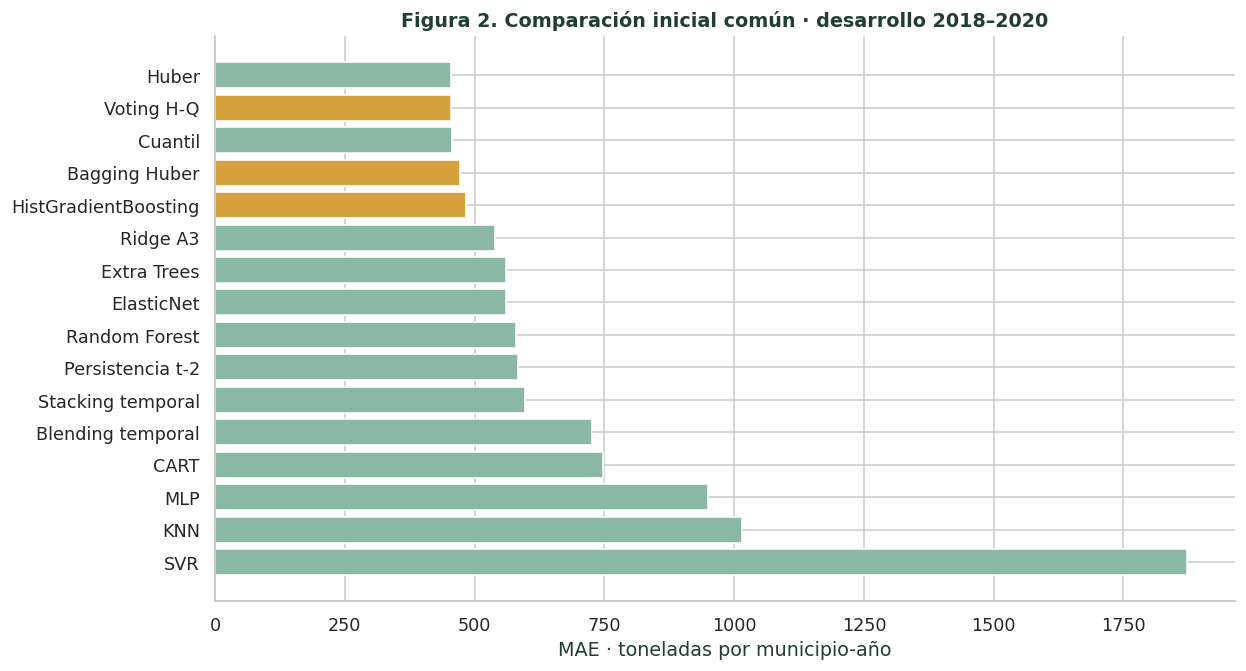

modelo,modelo,Huber,Cuantil,Bagging Huber,Random Forest,Extra Trees,HistGradientBoosting,Voting H-Q,Stacking temporal,Blending temporal
0,Huber,1.0000,1.0000,0.9920,0.7628,0.7824,0.8801,1.0000,0.9413,0.7783
1,Cuantil,1.0000,1.0000,0.9925,0.7639,0.7837,0.8809,1.0000,0.9419,0.7790
2,Bagging Huber,0.9920,0.9925,1.0000,0.8147,0.8358,0.9122,0.9922,0.9678,0.8341
3,Random Forest,0.7628,0.7639,0.8147,1.0000,0.9694,0.9298,0.7634,0.8815,0.8718
4,Extra Trees,0.7824,0.7837,0.8358,0.9694,1.0000,0.9317,0.7831,0.8949,0.8538
5,HistGradientBoosting,0.8801,0.8809,0.9122,0.9298,0.9317,1.0000,0.8805,0.9263,0.8244
6,Voting H-Q,1.0000,1.0000,0.9922,0.7634,0.7831,0.8805,1.0000,0.9416,0.7786
7,Stacking temporal,0.9413,0.9419,0.9678,0.8815,0.8949,0.9263,0.9416,1.0000,0.9067
8,Blending temporal,0.7783,0.7790,0.8341,0.8718,0.8538,0.8244,0.7786,0.9067,1.0000


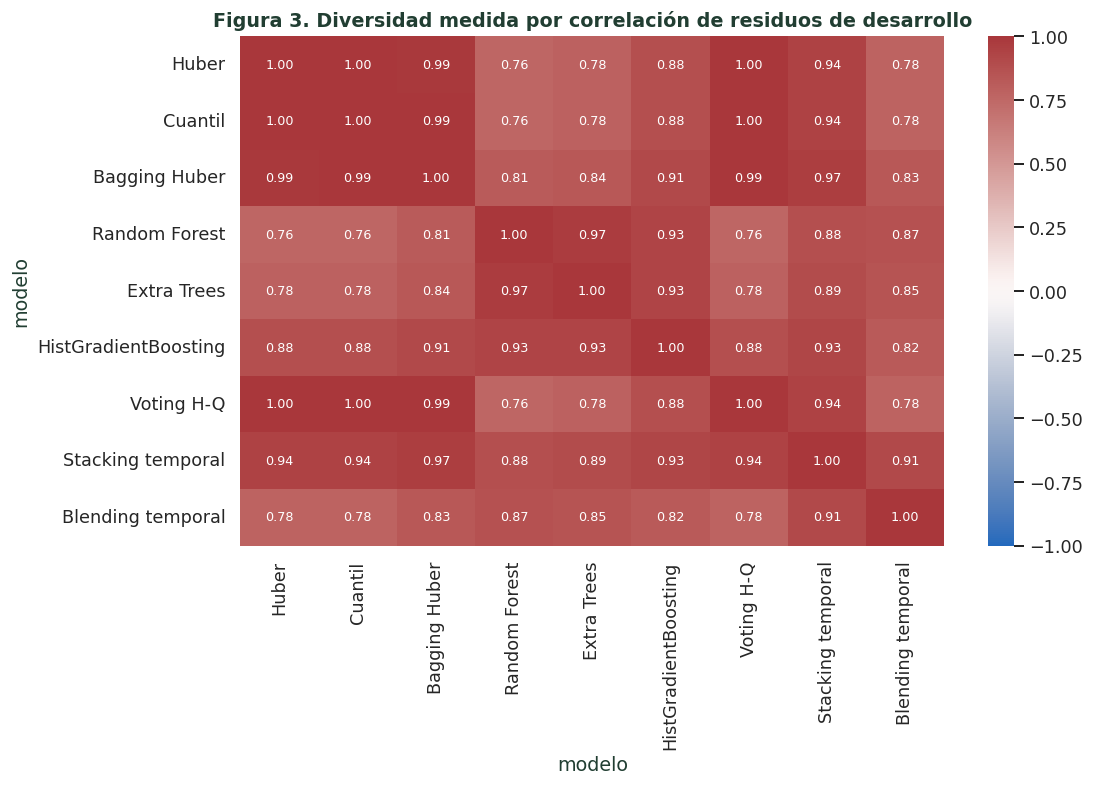

**Diversidad.** La correlación de residuos Huber–Cuantil es 1.0000. Una correlación alta limita la reducción de error mediante promedio, aunque los algoritmos tengan pérdidas distintas. Las relaciones se miden en desarrollo; no prueban independencia ni garantizan una mejora del ensamble.

In [4]:
initial_rows=[];initial_folds=[];initial_predictions=[];meta_audits=[]
for name in ENSEMBLES:
 s,d,p,a=evaluate(frame,name,INITIAL[name],previous,[2018,2019,2020],cache=False)
 initial_rows.append(s);initial_folds.append(d);initial_predictions.append(p)
 if not a.empty:meta_audits.append(a)
 print(name,'MAE',round(s['MAE_t'],3),'s',round(s['entrenamiento_s'],2),flush=True)
ensemble_dev=pd.DataFrame(initial_rows)
initial_table=pd.concat([individual_dev,ensemble_dev],ignore_index=True).sort_values('MAE_t')
table(initial_table,'06_comparativa_inicial_ordenada')
pd.concat(initial_folds,ignore_index=True).to_csv(OUT/'07_ensambles_iniciales_ventanas.csv',index=False)
relevant=choose_relevant(ensemble_dev)
(DOC/'modelos_relevantes.json').write_text(json.dumps({'modelos':relevant,'criterio':protocol['regla_relevancia']},ensure_ascii=False,indent=2))
display(Markdown('**Ensambles seleccionados para optimización:** '+', '.join(relevant)+'.'))
fig,ax=plt.subplots(figsize=(11,6))
colors_bar=['#D5A23D' if n in relevant else '#8BB8A3' for n in initial_table.modelo]
ax.barh(initial_table.modelo,initial_table.MAE_t,color=colors_bar);ax.invert_yaxis()
ax.set(title='Figura 2. Comparación inicial común · desarrollo 2018–2020',xlabel='MAE · toneladas por municipio-año')
figsave('fig02_comparativa_desarrollo')
dev_predictions=pd.concat(individual_predictions+initial_predictions,ignore_index=True)
dev_predictions.to_csv(OUT/'08_predicciones_desarrollo.csv',index=False)
wide=dev_predictions.pivot(index=['cvegeo','anio'],columns='modelo',values='prediccion_t')
truth=dev_predictions.drop_duplicates(['cvegeo','anio']).set_index(['cvegeo','anio']).produccion_t.reindex(wide.index)
residuals=wide.subtract(truth,axis=0)
corr=residuals[['Huber','Cuantil']+ENSEMBLES].corr()
table(corr.rename_axis('modelo').reset_index(),'09_correlacion_residuos')
fig,ax=plt.subplots(figsize=(10,7))
sns.heatmap(corr,vmin=-1,vmax=1,cmap='vlag',annot=True,fmt='.2f',ax=ax,annot_kws={'size':8})
ax.set_title('Figura 3. Diversidad medida por correlación de residuos de desarrollo')
figsave('fig03_diversidad')
hq_corr=float(corr.loc['Huber','Cuantil'])
display(Markdown(f'**Diversidad.** La correlación de residuos Huber–Cuantil es {hq_corr:.4f}. '
 'Una correlación alta limita la reducción de error mediante promedio, aunque los algoritmos tengan pérdidas distintas. '
 'Las relaciones se miden en desarrollo; no prueban independencia ni garantizan una mejora del ensamble.'))

### 3. Optimización reproducible de los modelos relevantes

Se ajustan **24 configuraciones distintas por cada uno de tres ensambles**, incluyendo siempre
la inicial. La relevancia se determina antes de optimizar: mejor homogéneo, mejor heterogéneo
y mejor modelo restante por MAE de desarrollo. La regla cubre ambas estrategias y asigna
esfuerzo a candidatos con evidencia favorable.

El catálogo se muestrea sin reemplazo con semillas fijas. Se exploran tamaño, profundidad,
remuestreo, número de variables o regularización según la familia. Huber y cuantílica conservan
los parámetros heredados en los ensambles heterogéneos. Se utilizan los mismos tres orígenes
2018–2020 para medir la mejora del ajuste, sin atribuirle cambios entre años diferentes.

La búsqueda usa una caché de bases y predicciones OOF calculadas exclusivamente con entrenamiento,
identificada por el contenido completo de sus entradas y etiquetas. Sus tiempos son costos reales
de experimentación con reutilización. Las comparativas inicial, de confirmación y de prueba
entrenan nuevamente sin caché, incluyen toda la preparación y el metamodelo, y sirven para
comparar costos completos. No se utiliza el tiempo para desempatar métricas.

La mejor configuración explorada no es necesariamente un óptimo global. La confirmación posterior
comprueba si la mejora de desarrollo se sostiene. Una configuración no convergente no puede ganar.

In [5]:
spaces=[];search_results={};search_folds={};chosen_configs={n:dict(INITIAL[n]) for n in ENSEMBLES}
for j,name in enumerate(relevant):
 space=parameter_space(name)
 spaces.append({'modelo':name,'catalogo':int(np.prod([len(v) for v in space.values()])),
                'configuraciones_evaluadas':24,'espacio':canonical(space)})
 res,details,best=tune(frame,name,previous,SEARCH,seed=42+j,budget=24)
 search_results[name]=res;search_folds[name]=details;chosen_configs[name]=best
 print('Optimizado',name,'mejor MAE',round(float(res.loc[res.convergencia,'MAE_t'].min()),3),flush=True)
table(pd.DataFrame(spaces),'10_espacios_busqueda')
(DOC/'configuraciones_ensambles.json').write_text(json.dumps(chosen_configs,ensure_ascii=False,indent=2))
print('Búsqueda completa: 72 configuraciones y 216 evaluaciones por ventana; iniciales incluidas.')

Optimizado Bagging Huber mejor MAE 467.081
Optimizado Voting H-Q mejor MAE 455.188
Optimizado HistGradientBoosting mejor MAE 470.104
Búsqueda completa: 72 configuraciones y 216 evaluaciones por ventana; iniciales incluidas.


,modelo,catalogo,configuraciones_evaluadas,espacio
0,Bagging Huber,36,24,"{""features"":[""completo"",""capacidad""],""max_features"":[0.75,1.0],""max_samples"":[0.6,0.8,1.0],""n_estimators"":[8,16,32],""target"":[""nivel""]}"
1,Voting H-Q,25,24,"{""peso_Huber"":[0.02,0.06,0.1,0.14,0.18,0.22,0.26,0.3,0.34,0.38,0.42,0.46,0.5,0.54,0.58,0.62,0.66,0.7,0.74,0.78,0.82,0.86,0.9,0.94,0.98]}"
2,HistGradientBoosting,972,24,"{""features"":[""completo"",""capacidad""],""l2_regularization"":[0.0,1.0,10.0],""learning_rate"":[0.025,0.05,0.1],""max_iter"":[60,100,180],""max_leaf_nodes"":[3,7,15],""min_samples_leaf"":[10,25,50],""target"":[""nivel"",""residuo""]}"


Confirmación ElasticNet 417.075
Confirmación Huber 283.389
Confirmación Cuantil 283.45
Confirmación CART 745.829
Confirmación KNN 836.171
Confirmación SVR 1324.771
Confirmación MLP 537.129
Confirmación Ridge A3 279.213
Confirmación Persistencia t-2 296.251
Confirmación Bagging Huber 286.632
Confirmación Random Forest 365.051
Confirmación Extra Trees 372.362
Confirmación HistGradientBoosting 299.325
Confirmación Voting H-Q 283.39
Confirmación Stacking temporal 414.521
Confirmación Blending temporal 400.867


,modelo,MAE_inicial_t,MAE_ajustado_t,mejora_pct,configuraciones,convergentes,configuracion,segundos_experimentacion_con_cache
0,Bagging Huber,471.5372,467.0814,0.9449,24,24,"{""features"":""capacidad"",""max_features"":1.0,""max_samples"":0.6,""n_estimators"":8,""target"":""nivel""}",364.3150
1,Voting H-Q,455.3472,455.1883,0.0349,24,24,"{""peso_Huber"":0.98}",7.9719
2,HistGradientBoosting,484.1047,470.1041,2.8920,24,24,"{""features"":""capacidad"",""l2_regularization"":1.0,""learning_rate"":0.1,""max_iter"":180,""max_leaf_nodes"":3,""min_samples_leaf"":25,""target"":""residuo""}",12.0820


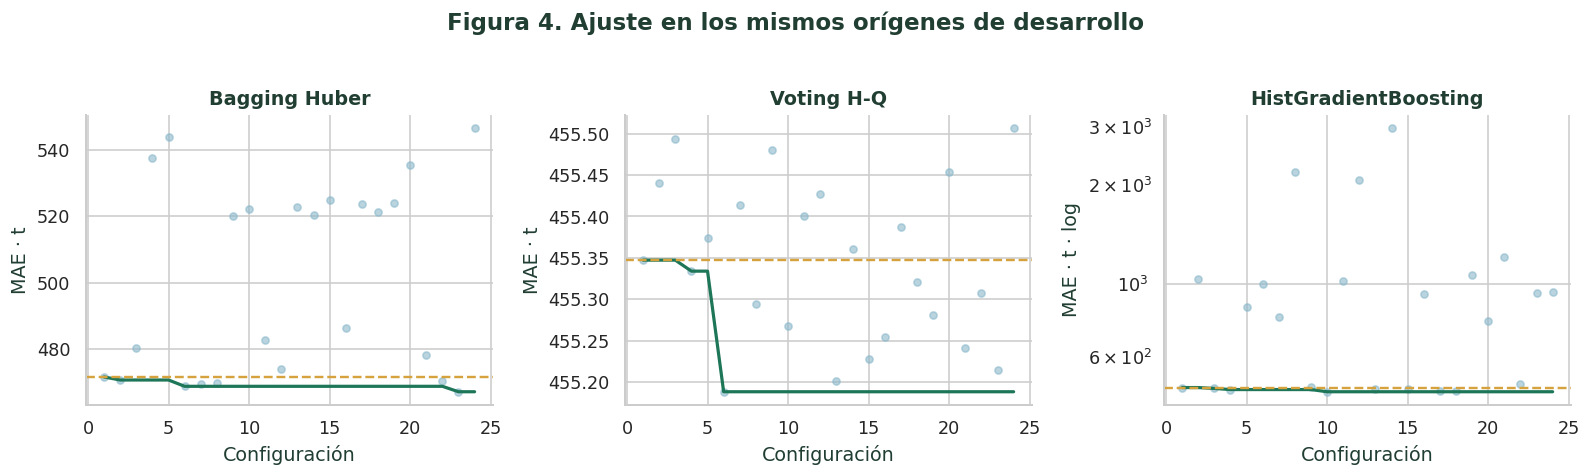

,modelo,estrategia,n,MAE_t,RMSE_t,WAPE_pct,sesgo_t,sesgo_pct,R2,RMSLE,entrenamiento_s,entrenamiento_promedio_s,prediccion_s,convergencia,cache
7,Ridge A3,Individual / referencia,1256,279.2133,"1,117.6332",7.0391,-41.0920,-1.0360,0.9969,0.6704,0.0104,0.0052,0.0031,True,False
1,Huber,Individual / referencia,1256,283.3891,"1,112.3704",7.1444,87.4203,2.2039,0.9969,0.8625,1.4071,0.7035,0.0044,True,False
13,Voting H-Q,Heterogéneo,1256,283.3903,"1,112.2943",7.1445,87.4341,2.2043,0.9969,0.8626,9.0626,4.5313,0.0072,True,False
2,Cuantil,Individual / referencia,1256,283.4502,"1,108.6459",7.1460,88.1059,2.2212,0.9969,0.8667,7.9288,3.9644,0.0045,True,False
9,Bagging Huber,Homogéneo,1256,286.6323,"1,081.5027",7.2262,86.2224,2.1737,0.9971,0.8560,1.9669,0.9834,0.0058,True,False
8,Persistencia t-2,Individual / referencia,1256,296.2510,"1,283.1433",7.4687,-229.2736,-5.7801,0.9959,0.6760,0.0000,0.0000,0.0001,True,False
12,HistGradientBoosting,Homogéneo,1256,299.3249,"1,098.8190",7.5462,90.6683,2.2858,0.9970,0.5961,0.5027,0.2513,0.0290,True,False
10,Random Forest,Homogéneo,1256,365.0511,"1,222.9443",9.2032,163.3674,4.1186,0.9963,0.8578,5.7089,2.8545,0.0360,True,False
11,Extra Trees,Homogéneo,1256,372.3622,"1,318.9691",9.3875,148.7609,3.7504,0.9957,0.7896,1.7403,0.8701,0.0294,True,False
15,Blending temporal,Heterogéneo,1256,400.8667,"1,534.4382",10.1061,240.2813,6.0576,0.9941,1.5627,3.6329,1.8165,0.0051,True,False


,modelo,MAE_t,RMSE_t,complejidad,dentro_1pct
7,Ridge A3,279.2133,"1,117.6332",1,True
1,Huber,283.3891,"1,112.3704",2,False
13,Voting H-Q,283.3903,"1,112.2943",4,False
2,Cuantil,283.4502,"1,108.6459",2,False
9,Bagging Huber,286.6323,"1,081.5027",7,False
8,Persistencia t-2,296.2510,"1,283.1433",0,False
12,HistGradientBoosting,299.3249,"1,098.8190",10,False
10,Random Forest,365.0511,"1,222.9443",9,False
11,Extra Trees,372.3622,"1,318.9691",9,False
15,Blending temporal,400.8667,"1,534.4382",5,False


**Modelo final elegido: Ridge A3.** Elección congelada antes de puntuar 2023 y 2025 en esta fase.

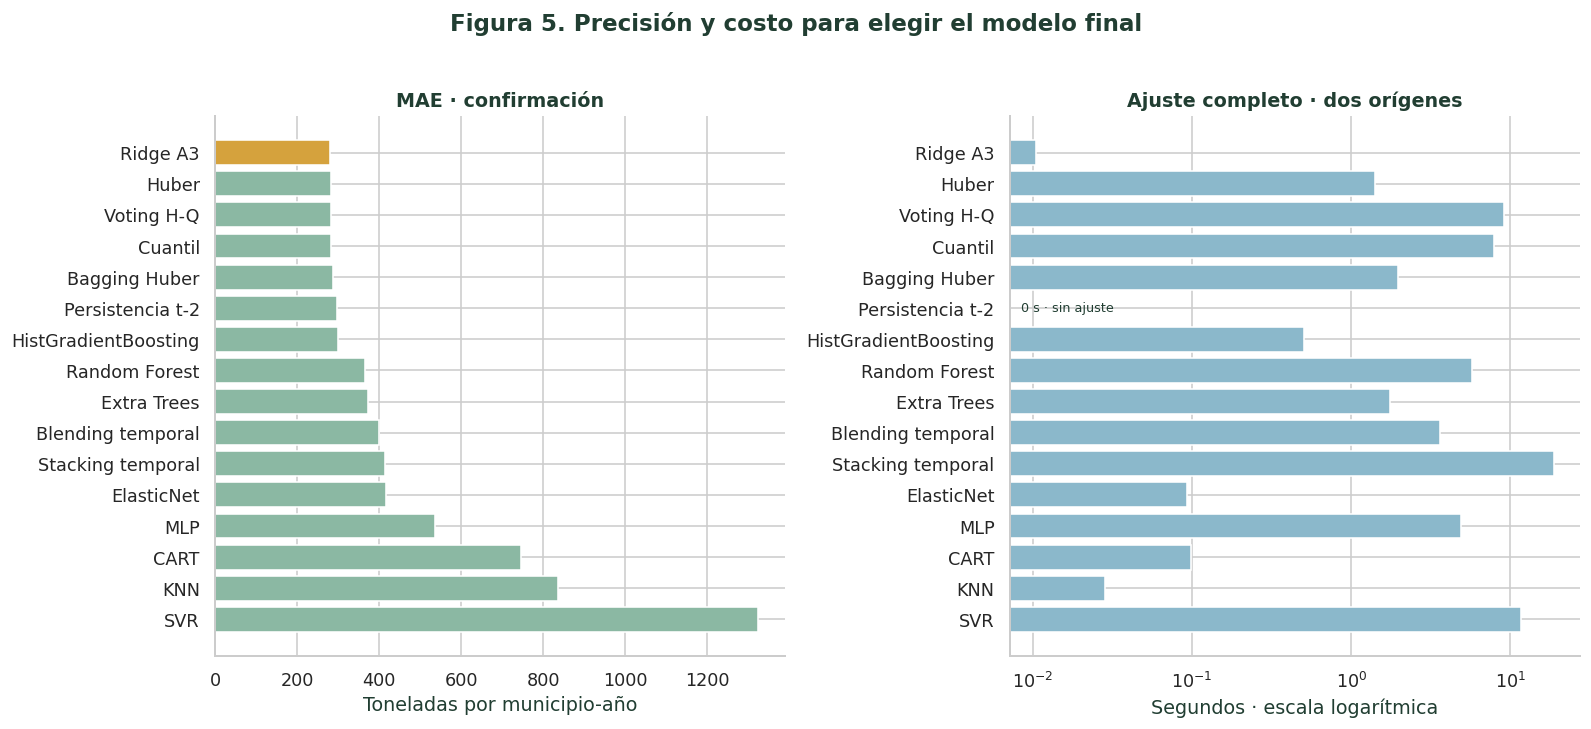

In [6]:
gains=[]
for name,res in search_results.items():
 first=res.loc[res.experimento.eq(1)].iloc[0]
 best=res.loc[res.config_id.eq(config_id(name,chosen_configs[name]))].iloc[0]
 gains.append({'modelo':name,'MAE_inicial_t':first.MAE_t,'MAE_ajustado_t':best.MAE_t,
  'mejora_pct':100*(1-best.MAE_t/first.MAE_t),'configuraciones':len(res),
  'convergentes':int(res.convergencia.sum()),'configuracion':canonical(chosen_configs[name]),
  'segundos_experimentacion_con_cache':float(res.entrenamiento_s.sum())})
gains=pd.DataFrame(gains);table(gains,'11_mejorias_ajuste')
fig,axes=plt.subplots(1,3,figsize=(14,4))
for ax,name in zip(axes,relevant):
 d=search_results[name].sort_values('experimento')
 ax.scatter(d.experimento,d.MAE_t,s=20,alpha=.6,color='#8BB8CB')
 ax.plot(d.experimento,d.MAE_t.cummin(),color='#1D7657',lw=2)
 ax.axhline(d.iloc[0].MAE_t,color='#D5A23D',ls='--')
 ax.set(title=name,xlabel='Configuración',ylabel='MAE · t')
 if d.MAE_t.max()/d.MAE_t.min()>3:ax.set_yscale('log');ax.set_ylabel('MAE · t · log')
fig.suptitle('Figura 4. Ajuste en los mismos orígenes de desarrollo',y=1.03,fontweight='bold')
figsave('fig04_busqueda')
names=ALGORITHMS+['Ridge A3','Persistencia t-2']+ENSEMBLES
confirmation_rows=[];confirmation_folds=[];confirmation_predictions=[]
for name in names:
 s,d,p,a=evaluate(frame,name,chosen_configs.get(name),previous,[2021,2022],cache=False)
 confirmation_rows.append(s);confirmation_folds.append(d);confirmation_predictions.append(p)
 if not a.empty:meta_audits.append(a)
 print('Confirmación',name,round(s['MAE_t'],3),flush=True)
confirmation=pd.DataFrame(confirmation_rows).sort_values('MAE_t')
table(confirmation,'12_comparativa_confirmacion_ordenada')
pd.concat(confirmation_folds,ignore_index=True).to_csv(OUT/'13_confirmacion_por_ventana.csv',index=False)
confirm_predictions=pd.concat(confirmation_predictions,ignore_index=True)
confirm_predictions.to_csv(OUT/'14_predicciones_confirmacion.csv',index=False)
winner,selection_table=select_final(confirmation)
selection={'modelo':winner,'configuracion':chosen_configs.get(winner,previous.get(winner,{})),
 'regla':protocol['regla_final'],'fase':'Confirmación 2021–2022','consulta_test_para_elegir':False}
(DOC/'seleccion_final_congelada.json').write_text(json.dumps(selection,ensure_ascii=False,indent=2))
selection_sha=hashlib.sha256((DOC/'seleccion_final_congelada.json').read_bytes()).hexdigest()
table(selection_table[['modelo','MAE_t','RMSE_t','complejidad','dentro_1pct']],'15_regla_eleccion')
display(Markdown(f'**Modelo final elegido: {winner}.** Elección congelada antes de puntuar 2023 y 2025 en esta fase.'))
fig,axes=plt.subplots(1,2,figsize=(14,6.2))
axes[0].barh(confirmation.modelo,confirmation.MAE_t,color=['#D5A23D' if x==winner else '#8BB8A3' for x in confirmation.modelo]);axes[0].invert_yaxis()
axes[0].set(title='MAE · confirmación',xlabel='Toneladas por municipio-año')
positive=confirmation.entrenamiento_s.gt(0).to_numpy();pos=np.arange(len(confirmation))
axes[1].barh(pos[positive],confirmation.loc[positive,'entrenamiento_s'],color='#8BB8CB')
axes[1].set(yticks=pos,yticklabels=confirmation.modelo,title='Ajuste completo · dos orígenes',xlabel='Segundos · escala logarítmica')
axes[1].set_xscale('log');axes[1].invert_yaxis()
for j,v in enumerate(confirmation.entrenamiento_s):
 if v==0:axes[1].text(.02,j,'0 s · sin ajuste',transform=axes[1].get_yaxis_transform(),va='center',fontsize=8)
fig.suptitle('Figura 5. Precisión y costo para elegir el modelo final',y=1.02,fontweight='bold')
figsave('fig05_confirmacion')

### 4. Elección de negocio y evaluación retrospectiva

La regla registrada favorece el menor MAE de confirmación. Si varias opciones quedan a menos
de 1% del mínimo, prefiere menor complejidad antes del desempate por MAE y nombre. La prioridad
se registra en código: persistencia, Ridge simple, regresiones individuales, árbol, combinación
de dos regresores, metamodelos y ensambles de mayor costo. Es una tolerancia técnica provisional,
no un umbral económico aprobado por el sponsor.

Las referencias también pueden ganar: aumentar complejidad no garantiza valor. Se documenta
si el mejor ensamble supera al mejor individual y si justifica su costo. Los tiempos de ajuste
se miden en esta máquina; la comparación no representa una garantía de latencia operativa.

Se puntúan todas las configuraciones congeladas sobre cohortes idénticas. Los modelos se
reajustan para cada origen con la historia permitida: 2007–2020 para 2023 y 2007–2022 para 2025.
Una tabla de prueba ordenada es descriptiva; **no cambia la elección registrada**.

In [7]:
test_rows=[];test_predictions_parts=[];final_models={}
for year in [2023,2025]:
 tr=frame.loc[frame.anio.between(2007,year-3)];te=frame.loc[frame.anio.eq(year)]
 for name in names:
    model=build(name,chosen_configs.get(name),previous).fit(tr,cache=False)
    started=time.perf_counter();raw_hat=model.predict_raw(te);pred=np.maximum(0,raw_hat);pred_s=time.perf_counter()-started
    test_rows.append({'modelo':name,'estrategia':strategy(name),'anio':year,**metrics(te.produccion_t,pred),
     'entrenamiento_s':model.fit_s_,'prediccion_s':pred_s,'convergencia':model.converged_,
     'negativas_limitadas':int((raw_hat<0).sum()),'fin_train':year-3,'n_train':len(tr)})
    p=te[['cvegeo','estado','anio','produccion_t','produccion_lag2']].copy();p['modelo']=name;p['prediccion_t']=pred
    test_predictions_parts.append(p)
    if name==winner:final_models[year]=model
    if not pd.DataFrame(model.audit_).empty:
        meta_audits.append(pd.DataFrame([{'modelo':name,'origen_externo':year,**a} for a in model.audit_]))
    pd.DataFrame(test_rows).to_csv(OUT/'prueba_en_progreso.csv',index=False)
    print('Prueba reutilizada',year,name,round(test_rows[-1]['MAE_t'],3),flush=True)
test_by_year=pd.DataFrame(test_rows);test_predictions=pd.concat(test_predictions_parts,ignore_index=True)
test_predictions.to_csv(OUT/'16_predicciones_pruebas.csv',index=False)
aggregate=[]
for name,p in test_predictions.groupby('modelo',sort=False):
 d=test_by_year.loc[test_by_year.modelo.eq(name)]
 aggregate.append({'modelo':name,'estrategia':strategy(name),**metrics(p.produccion_t,p.prediccion_t),
   'entrenamiento_s':float(d.entrenamiento_s.sum()),'prediccion_s':float(d.prediccion_s.sum()),
   'convergencia':bool(d.convergencia.all()),'seleccionado_previamente':name==winner})
test_comparison=pd.DataFrame(aggregate).sort_values('MAE_t')
table(test_comparison,'17_comparativa_pruebas_ordenada')
table(test_by_year.sort_values(['anio','MAE_t']),'18_metricas_por_anio')
model_final=final_models[2025];train_final=frame.loc[frame.anio.between(2007,2022)].copy()
test=frame.loc[frame.anio.eq(2025)].copy()
pred=model_final.predict(test)
reference=test_predictions.loc[test_predictions.anio.eq(2025)&test_predictions.modelo.eq('Huber')].set_index('cvegeo').prediccion_t
ref=reference.reindex(test.cvegeo).to_numpy()
metric_final=metrics(test.produccion_t,pred);metric_reference=metrics(test.produccion_t,ref)
skill=1-metric_final['MAE_t']/metric_reference['MAE_t']
train_metric=metrics(train_final.produccion_t,model_final.predict(train_final))
table(pd.DataFrame([{'conjunto':'Ajuste final 2007–2022',**train_metric},
 {'conjunto':'Prueba reutilizada 2025',**metric_final}]),'19_ajuste_y_prueba')

Prueba reutilizada 2023 ElasticNet 1040.212
Prueba reutilizada 2023 Huber 956.603
Prueba reutilizada 2023 Cuantil 944.114
Prueba reutilizada 2023 CART 1154.465
Prueba reutilizada 2023 KNN 1485.003
Prueba reutilizada 2023 SVR 3125.476
Prueba reutilizada 2023 MLP 1113.015
Prueba reutilizada 2023 Ridge A3 743.823
Prueba reutilizada 2023 Persistencia t-2 852.298
Prueba reutilizada 2023 Bagging Huber 698.103
Prueba reutilizada 2023 Random Forest 906.296
Prueba reutilizada 2023 Extra Trees 1017.161
Prueba reutilizada 2023 HistGradientBoosting 779.565
Prueba reutilizada 2023 Voting H-Q 956.353
Prueba reutilizada 2023 Stacking temporal 986.904
Prueba reutilizada 2023 Blending temporal 1032.282
Prueba reutilizada 2025 ElasticNet 498.867
Prueba reutilizada 2025 Huber 579.499
Prueba reutilizada 2025 Cuantil 582.832
Prueba reutilizada 2025 CART 569.499
Prueba reutilizada 2025 KNN 891.294
Prueba reutilizada 2025 SVR 3099.317
Prueba reutilizada 2025 MLP 690.63
Prueba reutilizada 2025 Ridge A3 755.34

,modelo,estrategia,n,MAE_t,RMSE_t,WAPE_pct,sesgo_t,sesgo_pct,R2,RMSLE,entrenamiento_s,prediccion_s,convergencia,seleccionado_previamente
9,Bagging Huber,Homogéneo,1284,690.3011,"5,760.1518",15.3848,1.9108,0.0426,0.9408,0.8060,1.7312,0.0053,True,False
8,Persistencia t-2,Individual / referencia,1284,748.5036,"6,222.9536",16.6819,-268.6550,-5.9875,0.9309,0.6997,0.0000,0.0001,True,False
7,Ridge A3,Individual / referencia,1284,749.6285,"6,284.7742",16.7070,-69.1778,-1.5418,0.9295,0.6895,0.0097,0.0028,True,True
12,HistGradientBoosting,Homogéneo,1284,752.9200,"6,085.7906",16.7804,9.2532,0.2062,0.9339,0.5686,0.3501,0.0136,True,False
2,Cuantil,Individual / referencia,1284,762.0659,"6,219.6558",16.9842,-278.2939,-6.2023,0.9310,0.8422,14.4845,0.0063,True,False
13,Voting H-Q,Heterogéneo,1284,766.4917,"6,238.9898",17.0828,-287.0923,-6.3984,0.9305,0.8449,17.1074,0.0093,True,False
1,Huber,Individual / referencia,1284,766.5823,"6,239.3898",17.0849,-287.2719,-6.4024,0.9305,0.8449,1.7613,0.0032,True,False
0,ElasticNet,Individual / referencia,1284,767.4313,"5,796.3014",17.1038,-322.1727,-7.1803,0.9400,1.9112,0.1251,0.0033,True,False
14,Stacking temporal,Heterogéneo,1284,774.2766,"6,035.2324",17.2563,-250.2235,-5.5767,0.9350,1.2189,34.9634,0.0063,True,False
15,Blending temporal,Heterogéneo,1284,777.5189,"5,889.9786",17.3286,-312.7320,-6.9699,0.9381,1.1955,13.3219,0.0069,True,False


,modelo,estrategia,anio,n,MAE_t,RMSE_t,WAPE_pct,sesgo_t,sesgo_pct,R2,RMSLE,entrenamiento_s,prediccion_s,convergencia,negativas_limitadas,fin_train,n_train
9,Bagging Huber,Homogéneo,2023,637,698.1030,"5,866.0015",14.9647,-492.1225,-10.5492,0.9477,0.7757,0.8734,0.0033,True,38,2020,6707
7,Ridge A3,Individual / referencia,2023,637,743.8233,"6,081.8800",15.9447,-643.2595,-13.7890,0.9438,0.7624,0.0055,0.0012,True,0,2020,6707
12,HistGradientBoosting,Homogéneo,2023,637,779.5649,"6,244.0568",16.7109,-514.5377,-11.0297,0.9408,0.5411,0.2034,0.0083,True,0,2020,6707
8,Persistencia t-2,Individual / referencia,2023,637,852.2975,"6,863.6403",18.2700,-829.9513,-17.7910,0.9285,0.7723,0.0000,0.0000,True,0,2020,6707
10,Random Forest,Homogéneo,2023,637,906.2958,"7,471.3778",19.4275,-764.0057,-16.3774,0.9152,0.6507,4.4418,0.0102,True,0,2020,6707
2,Cuantil,Individual / referencia,2023,637,944.1141,"7,437.2708",20.2382,-860.1138,-18.4376,0.9160,0.8146,4.2530,0.0023,True,23,2020,6707
13,Voting H-Q,Heterogéneo,2023,637,956.3525,"7,498.2210",20.5006,-872.9492,-18.7127,0.9146,0.8182,8.4661,0.0038,True,0,2020,6707
1,Huber,Individual / referencia,2023,637,956.6028,"7,499.4668",20.5059,-873.2111,-18.7183,0.9146,0.8183,0.9107,0.0018,True,24,2020,6707
14,Stacking temporal,Heterogéneo,2023,637,986.9040,"7,426.8447",21.1555,-743.8864,-15.9461,0.9162,1.4266,13.9641,0.0027,True,0,2020,6707
11,Extra Trees,Homogéneo,2023,637,"1,017.1608","8,448.4966",21.8041,-832.3798,-17.8431,0.8916,0.5995,0.7072,0.0091,True,0,2020,6707


,conjunto,n,MAE_t,RMSE_t,WAPE_pct,sesgo_t,sesgo_pct,R2,RMSLE
0,Ajuste final 2007–2022,7963,512.1852,"2,894.4767",14.7878,-207.1313,-5.9803,0.9758,1.0910
1,Prueba reutilizada 2025,647,755.3440,"6,478.3275",17.5190,496.0309,11.5046,0.9094,0.6094


### Lectura posterior de las pruebas y decisión de adopción

En 2025 el modelo seleccionado obtuvo 755.34 t de MAE
frente a 579.50 t de Huber A4: un deterioro relativo
de 30.34%.
Su ventaja de confirmación no se sostuvo frente a ese individual en ese año. Esto limita una
recomendación de adopción operativa.

En la evaluación concatenada 2023/2025, **Bagging Huber** obtuvo el menor MAE (690.30 t),
frente a 749.63 t de Ridge A3; reducción puntual de 7.91%. Es evidencia
posterior a la selección y no se utiliza para cambiar retrospectivamente al ganador.

Se entrega **Ridge A3 como predictor final seleccionado por el protocolo**, con sus límites.
La adopción operativa queda pendiente de evaluar en un periodo nuevo y de validar costos con el
sponsor. Bagging y Huber son comparadores prioritarios para esa evaluación futura. Los resultados
no sostienen la afirmación de que el ensamble o la referencia sean superiores en todos los años.


### 5. Cuatro gráficos principales del rendimiento final

El problema es de regresión continua; ROC, precisión-recall y matriz de confusión no corresponden
sin definir un evento categórico adicional. Las siguientes cuatro figuras responden preguntas
distintas sobre magnitud, dirección del error, calibración y cobertura territorial/productiva.
Las interpretaciones se calculan con el modelo elegido, sin cambiar su configuración.

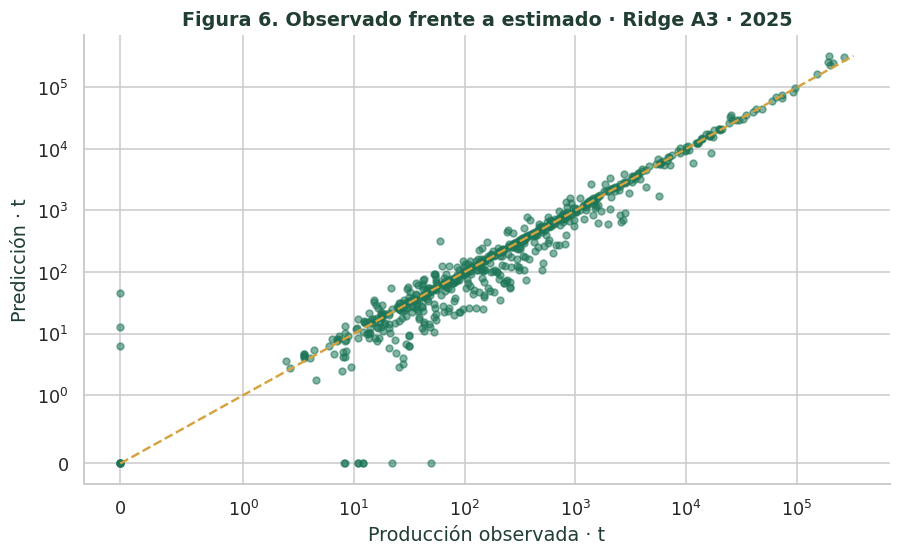

**Interpretación de la figura 6.** Cada punto es un municipio; la diagonal representa exactitud. En 647 municipios el MAE es 755.34 t y el RMSE 6,478.33 t. La diferencia entre ambas métricas cuantifica la influencia de errores grandes. La escala simétrica logarítmica permite conservar ceros y ver municipios pequeños y grandes; no transforma las métricas. Hay 8 objetivos cero; los errores cerca del origen requieren atención aunque su contribución al volumen total sea pequeña. La cercanía visual a la diagonal en escala logarítmica no sustituye la comparación de errores en toneladas.

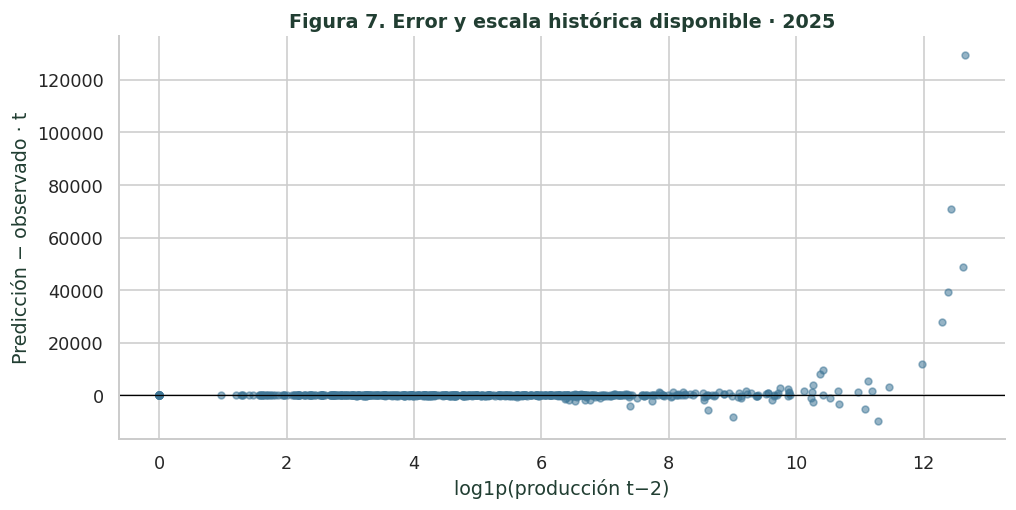

**Interpretación de la figura 7.** Un residuo positivo es sobreestimación y uno negativo es subestimación. El sesgo agregado es +11.50% y la mediana del residuo es 0.08 t. El mayor error absoluto es 129,472.35 t. La escala horizontal proviene de una entrada disponible, no del objetivo futuro. Una dispersión más amplia en municipios grandes implica riesgos de dimensionar mal la oferta y exige revisar casos individuales. Este gráfico describe heterogeneidad y dirección; por sí solo no demuestra sobreajuste, causalidad o error de fuente.

,grupo,n,observado_medio,estimado_medio
0,0,23,10.8196,1.3691
1,1,52,15.5471,8.4295
2,2,50,29.5826,18.1860
3,3,59,48.1254,31.5498
4,4,72,88.0604,58.0817
5,5,66,137.1697,104.9099
6,6,65,245.2111,202.7997
7,7,84,518.5799,456.3028
8,8,89,"1,352.2606","1,216.6037"
9,9,87,"29,758.2370","33,751.5284"


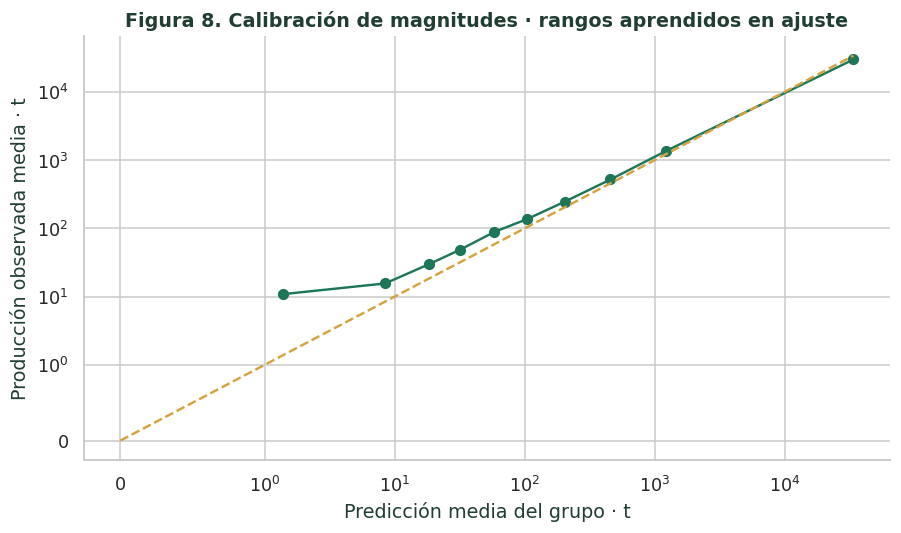

**Interpretación de la figura 8.** Los puntos agrupan municipios por rangos de predicción; sus límites proceden de las predicciones del entrenamiento y permanecen fijos para 2025. El rango con mayor separación contiene 87 municipios y difiere 3,993.29 t en promedio. Una curva sobre la diagonal indica subestimación del nivel medio y una curva debajo, sobreestimación. Las medias pueden ocultar errores que se compensan, por lo que se leen junto con MAE y residuos. Esta agrupación es un diagnóstico de magnitud, no una calibración probabilística ni un reajuste del modelo.

,grupo,n,MAE_t,RMSE_t,WAPE_pct,sesgo_t,sesgo_pct,R2,RMSLE,MAE_Huber_t
0,Q1,98,8.9476,14.1015,55.9643,-7.5943,-47.5001,-0.2062,1.0846,31.7108
1,Q2,158,29.0178,56.9139,45.1735,-22.4651,-34.9726,0.0330,0.6915,31.5396
2,Q3,171,59.1129,112.6424,25.1662,-36.0443,-15.3452,0.4184,0.4184,57.0972
3,Q4,220,"2,150.6253","11,109.1825",17.2823,"1,506.3150",12.1046,0.9023,0.2976,"1,623.0964"


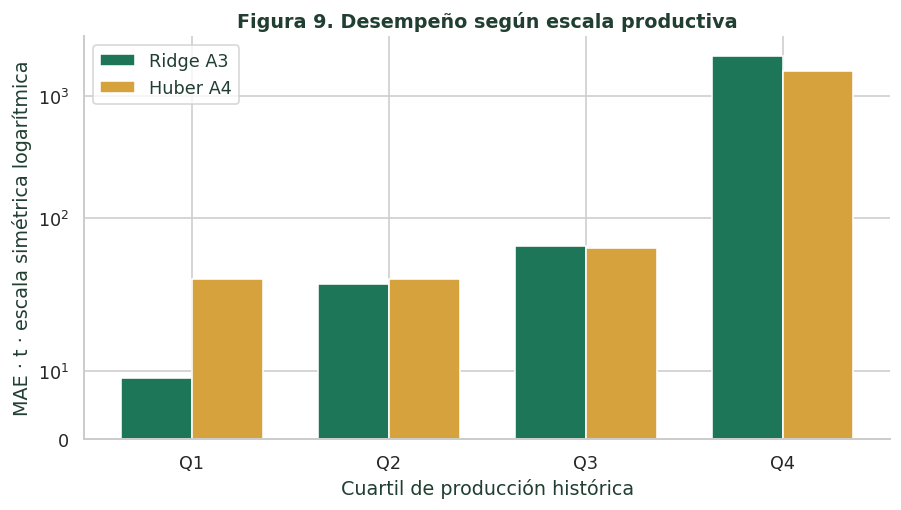

**Interpretación de la figura 9.** Los cuartiles se definen con producción t−2 del entrenamiento, sin escoger límites para favorecer el resultado de prueba. El grupo de menor escala tiene MAE 8.95 t y el de mayor escala 2,150.63 t. La comparación con Huber A4 muestra si la mejora agregada se reparte entre segmentos o depende de un estrato. La escala logarítmica solo facilita visualizar diferencias. La priorización de atención debe combinar volumen, error relativo y costo operativo; un MAE pequeño en productores pequeños no garantiza un servicio adecuado para ellos.

In [8]:
residual=pred-test.produccion_t.to_numpy();ae=np.abs(residual)
fig,ax=plt.subplots(figsize=(8,5))
limit=max(test.produccion_t.max(),pred.max());ax.scatter(test.produccion_t,pred,s=18,alpha=.55,color='#1D7657')
ax.plot([0,limit],[0,limit],ls='--',color='#D5A23D');ax.set_xscale('symlog',linthresh=1);ax.set_yscale('symlog',linthresh=1)
ax.set(title=f'Figura 6. Observado frente a estimado · {winner} · 2025',xlabel='Producción observada · t',ylabel='Predicción · t')
figsave('fig06_observado_estimado')
display(Markdown(f'**Interpretación de la figura 6.** Cada punto es un municipio; la diagonal representa exactitud. '
 f'En {len(test)} municipios el MAE es {metric_final["MAE_t"]:,.2f} t y el RMSE {metric_final["RMSE_t"]:,.2f} t. '
 'La diferencia entre ambas métricas cuantifica la influencia de errores grandes. La escala simétrica logarítmica '
 'permite conservar ceros y ver municipios pequeños y grandes; no transforma las métricas. '
 f'Hay {int(test.produccion_t.eq(0).sum())} objetivos cero; los errores cerca del origen requieren atención '
 'aunque su contribución al volumen total sea pequeña. La cercanía visual a la diagonal en escala logarítmica '
 'no sustituye la comparación de errores en toneladas.'))
fig,ax=plt.subplots(figsize=(9,4.6))
ax.scatter(np.log1p(test.produccion_lag2),residual,s=18,alpha=.55,color='#407797');ax.axhline(0,color='black',lw=.8)
ax.set(title='Figura 7. Error y escala histórica disponible · 2025',xlabel='log1p(producción t−2)',ylabel='Predicción − observado · t')
figsave('fig07_residuos')
display(Markdown(f'**Interpretación de la figura 7.** Un residuo positivo es sobreestimación y uno negativo es '
 f'subestimación. El sesgo agregado es {metric_final["sesgo_pct"]:+.2f}% y la mediana del residuo es '
 f'{np.median(residual):,.2f} t. El mayor error absoluto es {ae.max():,.2f} t. '
 'La escala horizontal proviene de una entrada disponible, no del objetivo futuro. Una dispersión más amplia '
 'en municipios grandes implica riesgos de dimensionar mal la oferta y exige revisar casos individuales. '
 'Este gráfico describe heterogeneidad y dirección; por sí solo no demuestra sobreajuste, causalidad o error de fuente.'))
q_edges=np.r_[-np.inf,np.unique(np.quantile(model_final.predict(train_final),np.arange(.1,1,.1))),np.inf]
cal=pd.DataFrame({'observado':test.produccion_t.to_numpy(),'estimado':pred})
cal['grupo']=pd.cut(cal.estimado,q_edges,labels=False,include_lowest=True)
calibration=cal.groupby('grupo',observed=True).agg(n=('observado','size'),observado_medio=('observado','mean'),estimado_medio=('estimado','mean')).reset_index()
table(calibration,'20_calibracion_por_rango')
fig,ax=plt.subplots(figsize=(8,4.8))
ax.plot(calibration.estimado_medio,calibration.observado_medio,marker='o',color='#1D7657')
lim=max(calibration.estimado_medio.max(),calibration.observado_medio.max())
ax.plot([0,lim],[0,lim],ls='--',color='#D5A23D');ax.set_xscale('symlog',linthresh=1);ax.set_yscale('symlog',linthresh=1)
ax.set(title='Figura 8. Calibración de magnitudes · rangos aprendidos en ajuste',xlabel='Predicción media del grupo · t',ylabel='Producción observada media · t')
figsave('fig08_calibracion')
worst_cal=calibration.assign(desvio=lambda d:(d.observado_medio-d.estimado_medio).abs()).sort_values('desvio',ascending=False).iloc[0]
display(Markdown(f'**Interpretación de la figura 8.** Los puntos agrupan municipios por rangos de predicción; '
 'sus límites proceden de las predicciones del entrenamiento y permanecen fijos para 2025. '
 f'El rango con mayor separación contiene {int(worst_cal.n)} municipios y difiere '
 f'{abs(worst_cal.observado_medio-worst_cal.estimado_medio):,.2f} t en promedio. '
 'Una curva sobre la diagonal indica subestimación del nivel medio y una curva debajo, sobreestimación. '
 'Las medias pueden ocultar errores que se compensan, por lo que se leen junto con MAE y residuos. '
 'Esta agrupación es un diagnóstico de magnitud, no una calibración probabilística ni un reajuste del modelo.'))
edges=np.r_[-np.inf,np.unique(train_final.produccion_lag2.quantile([.25,.5,.75]).to_numpy()),np.inf]
diagnostic=test[['cvegeo','estado','anio','produccion_t','produccion_lag2']].copy()
diagnostic['prediccion_t']=pred;diagnostic['Huber_A4_t']=ref;diagnostic['residuo_t']=residual;diagnostic['error_absoluto_t']=ae
diagnostic['grupo_tamano']=pd.cut(test.produccion_lag2,edges,labels=[f'Q{i+1}' for i in range(len(edges)-1)],include_lowest=True).astype(str)
segments=[]
for name,d in diagnostic.groupby('grupo_tamano',observed=True):
 segments.append({'grupo':name,**metrics(d.produccion_t,d.prediccion_t),'MAE_Huber_t':metrics(d.produccion_t,d.Huber_A4_t)['MAE_t']})
size=pd.DataFrame(segments);table(size,'21_error_por_tamano')
fig,ax=plt.subplots(figsize=(8,4.6));x=np.arange(len(size))
ax.bar(x-.18,size.MAE_t,.36,label=winner,color='#1D7657');ax.bar(x+.18,size.MAE_Huber_t,.36,label='Huber A4',color='#D5A23D')
ax.set_yscale('symlog',linthresh=20);ax.set(xticks=x,xticklabels=size.grupo,xlabel='Cuartil de producción histórica',ylabel='MAE · t · escala simétrica logarítmica',title='Figura 9. Desempeño según escala productiva');ax.legend()
figsave('fig09_segmentos')
display(Markdown(f'**Interpretación de la figura 9.** Los cuartiles se definen con producción t−2 del '
 'entrenamiento, sin escoger límites para favorecer el resultado de prueba. '
 f'El grupo de menor escala tiene MAE {size.iloc[0].MAE_t:,.2f} t y el de mayor escala '
 f'{size.iloc[-1].MAE_t:,.2f} t. La comparación con Huber A4 muestra si la mejora agregada se reparte '
 'entre segmentos o depende de un estrato. La escala logarítmica solo facilita visualizar diferencias. '
 'La priorización de atención debe combinar volumen, error relativo y costo operativo; un MAE pequeño '
 'en productores pequeños no garantiza un servicio adecuado para ellos.'))

,anio,municipios,observado_t,predicho_t
0,2021,620,"2,442,546.6900","2,413,546.8062"
1,2022,620,"2,538,853.9100","2,515,134.5151"
2,2023,620,"2,969,440.7200","2,561,450.6494"
3,2025,620,"2,785,903.8700","3,106,468.0635"


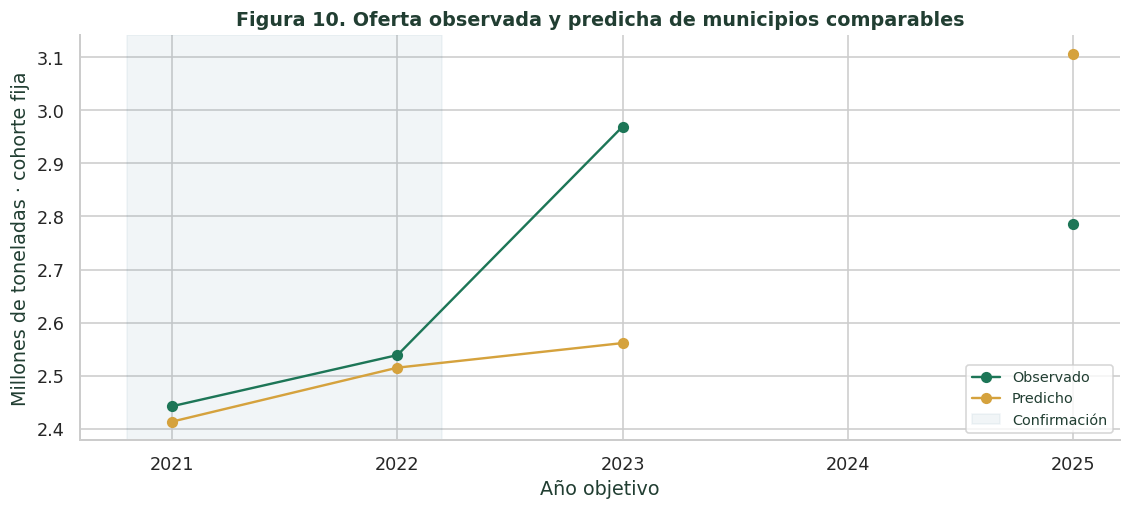

**Interpretación de la figura 10.** Se conservan los mismos 620 municipios en los cuatro años para reducir cambios de cobertura. Los puntos 2021–2022 participaron en la elección; 2023 y 2025 son pruebas retrospectivas reutilizadas. El hueco de 2024 se muestra sin interpolar, pues ese año permanece en cuarentena. Las líneas comparan volumen de esta cohorte, no producción nacional ni una serie mensual. La cancelación de errores municipales puede acercar los totales aun con MAE elevado; por eso esta figura acompaña, y no reemplaza, los diagnósticos anteriores.

In [9]:
selected_history=pd.concat([confirm_predictions,test_predictions],ignore_index=True)
selected_history=selected_history.loc[selected_history.modelo.eq(winner)].copy()
years=[2021,2022,2023,2025]
common=set.intersection(*(set(selected_history.loc[selected_history.anio.eq(y),'cvegeo']) for y in years))
trajectory=selected_history.loc[selected_history.cvegeo.isin(common)].groupby('anio').agg(
 municipios=('cvegeo','nunique'),observado_t=('produccion_t','sum'),predicho_t=('prediccion_t','sum')).reset_index()
table(trajectory,'22_tendencia_cohorte_comun')
fig,ax=plt.subplots(figsize=(10,4.6))
timeline=trajectory.set_index('anio').reindex(range(2021,2026))
ax.plot(timeline.index,timeline.observado_t/1e6,marker='o',color='#1D7657',label='Observado')
ax.plot(timeline.index,timeline.predicho_t/1e6,marker='o',color='#D5A23D',label='Predicho')
ax.axvspan(2020.8,2022.2,color='#407797',alpha=.07,label='Confirmación')
ax.set(xticks=range(2021,2026),xlabel='Año objetivo',ylabel='Millones de toneladas · cohorte fija',title='Figura 10. Oferta observada y predicha de municipios comparables');ax.legend(fontsize=9)
figsave('fig10_tendencia')
display(Markdown(f'**Interpretación de la figura 10.** Se conservan los mismos {len(common)} municipios '
 'en los cuatro años para reducir cambios de cobertura. Los puntos 2021–2022 participaron en la elección; '
 '2023 y 2025 son pruebas retrospectivas reutilizadas. El hueco de 2024 se muestra sin interpolar, pues '
 'ese año permanece en cuarentena. Las líneas comparan volumen de esta cohorte, no producción nacional '
 'ni una serie mensual. La cancelación de errores municipales puede acercar los totales aun con MAE elevado; '
 'por eso esta figura acompaña, y no reemplaza, los diagnósticos anteriores.'))

,n_replicas,semilla,estados,skill_puntual,percentil_2_5,percentil_97_5,referencia,unidad_remuestreo
0,1500,42,29,-0.3034,-0.4079,0.1157,Huber A4,estado


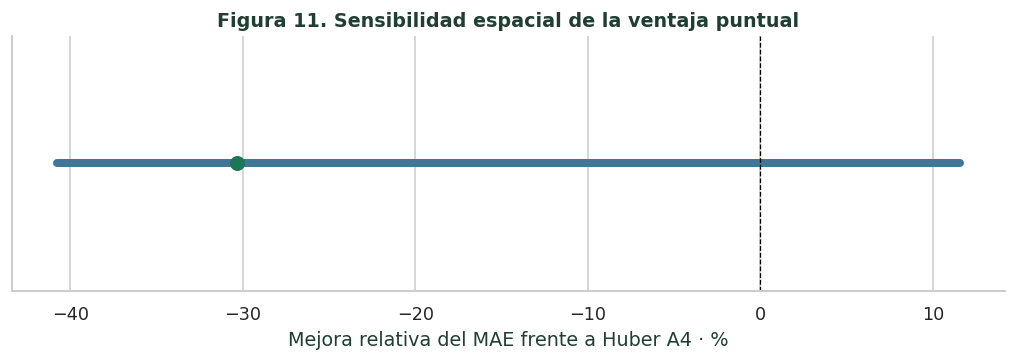

**Interpretación de la figura 11.** Se remuestrean estados completos de forma emparejada 1,500 veces. La mejora puntual es -30.34% y los percentiles 2.5–97.5 son [-40.79%, +11.57%]. El rango cruza cero: no sostiene superioridad uniforme bajo otra composición estatal. El resultado se condiciona a 2025 y a modelos ya ajustados; no incluye variación de entrenamiento ni incertidumbre de futuros años.

In [10]:
bootstrap=state_bootstrap(test,pred,ref,n_boot=1500,seed=42)
table(pd.DataFrame([{**bootstrap,'referencia':'Huber A4','unidad_remuestreo':'estado'}]),'23_sensibilidad_estatal')
lo,hi=100*bootstrap['percentil_2_5'],100*bootstrap['percentil_97_5']
fig,ax=plt.subplots(figsize=(9,3.3))
ax.plot([lo,hi],[0,0],lw=5,color='#407797');ax.scatter([100*skill],[0],s=70,color='#1D7657',zorder=3)
ax.axvline(0,ls='--',color='black',lw=.8)
ax.set(yticks=[],xlabel='Mejora relativa del MAE frente a Huber A4 · %',title='Figura 11. Sensibilidad espacial de la ventaja puntual')
if lo==hi:ax.set_xlim(lo-1,hi+1)
figsave('fig11_sensibilidad')
display(Markdown(f'**Interpretación de la figura 11.** Se remuestrean estados completos de forma emparejada '
 f'1,500 veces. La mejora puntual es {100*skill:+.2f}% y los percentiles 2.5–97.5 son '
 f'[{lo:+.2f}%, {hi:+.2f}%]. '
 +('El rango cruza cero: no sostiene superioridad uniforme bajo otra composición estatal. ' if lo<=0<=hi else 'El rango no cruza cero en esta cohorte, sin equivaler a certeza prospectiva. ')
 +'El resultado se condiciona a 2025 y a modelos ya ajustados; no incluye variación de entrenamiento ni incertidumbre de futuros años.'))

,estado,entidad,n,MAE_t,RMSE_t,WAPE_pct,sesgo_t,sesgo_pct,R2,RMSLE,MAE_Huber_t,volumen_t
13,16,Michoacán,66,"5,569.5771","20,135.0893",18.1119,"4,957.3275",16.1209,0.8865,0.2217,"3,925.6012","2,029,556.0200"
15,18,Nayarit,13,"1,524.9361","2,837.8561",26.9039,495.0934,8.7347,0.8961,0.6732,"1,251.0413","73,685.2400"
7,10,Durango,6,999.8168,"1,335.4628",72.2331,-999.8168,-72.2331,-0.1791,1.4085,662.4247,"8,304.9200"
12,15,Estado de México,32,740.5833,"1,849.0981",17.9226,198.8747,4.8129,0.8996,0.2595,413.9768,"132,227.5800"
14,17,Morelos,13,519.1552,"1,028.0417",13.5671,482.3878,12.6062,0.9658,0.1047,514.4961,"49,745.5700"
11,14,Jalisco,78,435.8720,"1,350.4583",9.6902,-162.8744,-3.6210,0.9826,0.3232,542.8542,"350,848.2200"
16,19,Nuevo León,9,411.4589,731.0692,66.4479,-408.6692,-65.9974,0.3581,1.3824,315.6137,"5,572.9800"
19,22,Querétaro,6,182.5779,197.1897,70.6102,-182.5779,-70.6102,-3.1113,1.2074,170.9306,"1,551.4300"
21,25,Sinaloa,6,162.7840,287.5572,26.2918,131.1455,21.1818,0.8552,0.3890,121.8080,"3,714.8600"
0,01,Aguascalientes,1,153.2224,153.2224,21.1036,-153.2224,-21.1036,NaN,0.2367,158.5585,726.0500


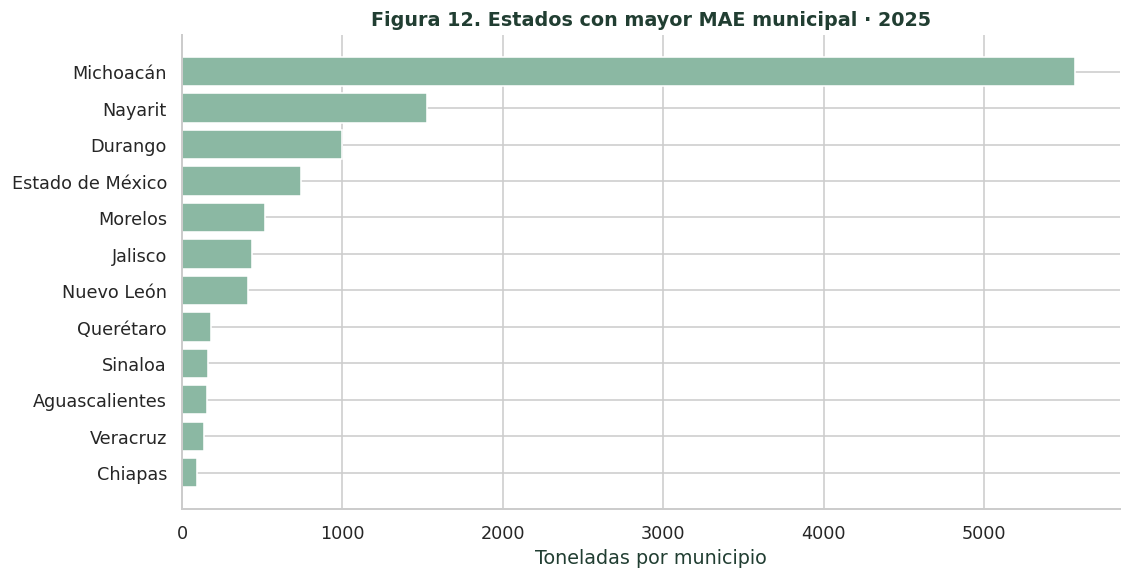

,cvegeo,estado,anio,produccion_t,produccion_lag2,prediccion_t,Huber_A4_t,residuo_t,error_absoluto_t,grupo_tamano,MUNICIPIO,ENTIDAD
0,16082,16,2025,"196,028.4000","311,142.8000","325,500.7466","290,366.2037","129,472.3466","129,472.3466",Q4,Tacámbaro,Michoacán
1,16079,16,2025,"190,839.7000","249,975.0000","261,510.3070","242,126.0336","70,670.6070","70,670.6070",Q4,Salvador Escalante,Michoacán
2,16083,16,2025,"268,975.9000","303,620.0000","317,630.8007","302,028.1287","48,654.9007","48,654.9007",Q4,Tancítaro,Michoacán
3,16009,16,2025,"211,762.7000","239,965.5400","251,038.9520","238,635.7247","39,276.2520","39,276.2520",Q4,Ario,Michoacán
4,16102,16,2025,"201,170.3800","219,011.0000","229,117.4471","218,772.1413","27,947.0671","27,947.0671",Q4,Uruapan,Michoacán
5,16068,16,2025,"153,789.1700","158,513.0000","165,827.7159","154,567.8513","12,038.5459","12,038.5459",Q4,Peribán,Michoacán
6,15021,15,2025,"25,648.3500","33,772.9000","35,331.3789","30,898.7934","9,683.0289","9,683.0289",Q4,Coatepec Harinas,Estado de México
7,16075,16,2025,"92,452.1200","79,173.1300","82,826.6408","81,083.7765","-9,625.4792","9,625.4792",Q4,Los Reyes,Michoacán
8,14086,14,2025,"16,807.9200","8,121.3000","8,496.0642","7,779.9069","-8,311.8558","8,311.8558",Q4,Tapalpa,Jalisco
9,18008,18,2025,"24,962.9000","31,791.5100","33,258.5560","32,580.9303","8,295.6560","8,295.6560",Q4,Xalisco,Nayarit


,segmento,n,MAE_t,RMSE_t,WAPE_pct,sesgo_t,sesgo_pct,R2,RMSLE
0,Antecedente cero,13,10.2885,16.5944,100.0000,-10.2885,-100.0000,-0.6244,2.1585
1,Antecedente positivo,634,770.6211,"6,544.4083",17.5150,506.4128,11.5100,0.9094,0.5324


**Lectura territorial.** El mayor MAE estatal corresponde a Michoacán, con 5,569.58 t por municipio. Los diez casos de mayor error concentran 74.48% del error absoluto. Los extremos válidos se mantienen y se listan para revisión. La temperatura estatal y las variables macro anuales no sustituyen información local de clima, manejo, plagas, demanda o disponibilidad de agua. Los resultados justifican seguimiento territorial, sin inferir causas.

In [11]:
states=[]
for state,d in diagnostic.groupby('estado'):
 states.append({'estado':state,'entidad':STATE_NAMES[int(state)-1],**metrics(d.produccion_t,d.prediccion_t),
  'MAE_Huber_t':metrics(d.produccion_t,d.Huber_A4_t)['MAE_t'],'volumen_t':float(d.produccion_t.sum())})
states=pd.DataFrame(states).sort_values('MAE_t',ascending=False);table(states,'24_resultados_estatales')
fig,ax=plt.subplots(figsize=(10,5.2));top=states.head(12).sort_values('MAE_t')
ax.barh(top.entidad,top.MAE_t,color='#8BB8A3');ax.set(title='Figura 12. Estados con mayor MAE municipal · 2025',xlabel='Toneladas por municipio')
figsave('fig12_estados')
worst=diagnostic.nlargest(15,'error_absoluto_t').merge(
 panel.loc[panel.anio.eq(2025),['cvegeo','MUNICIPIO','ENTIDAD']],on='cvegeo',how='left',validate='one_to_one')
table(worst,'25_municipios_mayor_error')
zero_rows=[]
for label,mask in [('Antecedente cero',test.produccion_lag2.eq(0)),('Antecedente positivo',test.produccion_lag2.gt(0))]:
 if mask.any():zero_rows.append({'segmento':label,**metrics(test.loc[mask,'produccion_t'],pred[mask.to_numpy()])})
table(pd.DataFrame(zero_rows),'26_historia_cero')
concentration=100*diagnostic.nlargest(10,'error_absoluto_t').error_absoluto_t.sum()/diagnostic.error_absoluto_t.sum()
display(Markdown(f'**Lectura territorial.** El mayor MAE estatal corresponde a {states.iloc[0].entidad}, '
 f'con {states.iloc[0].MAE_t:,.2f} t por municipio. Los diez casos de mayor error concentran '
 f'{concentration:.2f}% del error absoluto. Los extremos válidos se mantienen y se listan para revisión. '
 'La temperatura estatal y las variables macro anuales no sustituyen información local de clima, manejo, '
 'plagas, demanda o disponibilidad de agua. Los resultados justifican seguimiento territorial, sin inferir causas.'))

### 6. Calidad, restricciones y trazabilidad

Se verifican los bytes heredados, cohortes, ventanas externas e internas, cantidad y diversidad
de modelos, convergencia, presupuesto de búsqueda y separación entre selección y prueba.
El modelo final debe producir valores finitos y no negativos, no consultar y al predecir,
no cambiar sus parámetros durante inferencia y conservar resultados al guardar/restaurar.

Los controles de integridad no convierten un resultado desfavorable en un fallo de programación.
Se reportan las métricas sin reabrir la búsqueda. La ausencia de una prueba global nueva, la
concentración territorial, la cuarentena y las fechas de publicación siguen siendo restricciones.

In [12]:
checks=[]
def check(name,condition,evidence):
 assert bool(condition),name
 checks.append({'control':name,'estado':'OK','evidencia':str(evidence)})
check('Agricultura original',hashlib.sha256((ROOT/'data/raw/siap_produccion.csv').read_bytes()).hexdigest()==RAW_SHA256,RAW_SHA256)
for entry in previous_manifest['entradas_verificadas']:
 check('Continuidad '+entry['ruta'],hashlib.sha256((ROOT/entry['ruta']).read_bytes()).hexdigest()==entry['sha256'],entry['sha256'])
verify_external_files(ROOT/'data/externos')
check('Panel sin claves duplicadas',not frame.duplicated(['cvegeo','anio']).any(),len(frame))
check('Cuarentenas conservadas',len(history)==981 and len(quarantine)==900 and not panel.anio.eq(2024).any() and not temperature.anio_medicion.eq(2013).any(),'2024 agrícola y 2013 climático')
check('Siete ensambles',len(ENSEMBLES)==7 and len(set(ENSEMBLES))==7,ENSEMBLES)
check('Dos estrategias',len(HOMOGENEOUS)==4 and len(HETEROGENEOUS)==3,[HOMOGENEOUS,HETEROGENEOUS])
check('Bases mejores A4',set(previous)=={'Huber','Cuantil'},previous)
check('Tres relevantes con ambas estrategias',len(relevant)==3 and bool(set(relevant)&set(HOMOGENEOUS)) and bool(set(relevant)&set(HETEROGENEOUS)),relevant)
check('72 configuraciones distintas',sum(len(x) for x in search_results.values())==72 and all(x.config_id.nunique()==24 for x in search_results.values()),72)
check('216 evaluaciones por ventana',sum(len(x) for x in search_folds.values())==216,216)
check('Comparativa inicial completa',set(initial_table.modelo)==set(names) and len(initial_table)==16,len(initial_table))
check('Orden por métrica principal',confirmation.MAE_t.is_monotonic_increasing and test_comparison.MAE_t.is_monotonic_increasing,'MAE ascendente')
check('Convergencia comparativa confirmación',confirmation.convergencia.all(),confirmation[['modelo','convergencia']].to_dict('records'))
check('Convergencia pruebas',test_by_year.convergencia.all(),len(test_by_year))
check('Separación temporal externa',(test_by_year.fin_train<=test_by_year.anio-3).all() and (windows.fin_train<=windows.anio-3).all(),'Etiquetas hasta t−3')
all_audits=pd.concat(meta_audits,ignore_index=True)
check('Metamodelos con separación interna',(all_audits.max_etiqueta_base<=all_audits.anio_meta-3).all(),len(all_audits))
all_audits.to_csv(OUT/'27_auditoria_metamodelos.csv',index=False)
for path in SEARCH.glob('*_auditoria_meta.csv'):
 d=pd.read_csv(path);check('OOF búsqueda '+path.stem,(d.max_etiqueta_base<=d.anio_meta-3).all(),len(d))
check('Selección sin consultar pruebas',not selection['consulta_test_para_elegir'] and selection['fase']=='Confirmación 2021–2022',winner)
check('Protocolo intacto',hashlib.sha256((DOC/'protocolo_evaluacion.json').read_bytes()).hexdigest()==protocol_sha,protocol_sha)
check('Elección congelada intacta',hashlib.sha256((DOC/'seleccion_final_congelada.json').read_bytes()).hexdigest()==selection_sha,selection_sha)
check('Ajuste final hasta 2022',model_final.train_end_==2022 and model_final.n_train_==len(train_final),len(train_final))
check('Prueba excluida de ajuste',not train_final.anio.isin([2023,2025]).any(),'2007–2022')
altered=test.copy();altered['produccion_t']=altered.produccion_t*97+43
check('y no interviene en predicción',np.array_equal(model_final.predict(altered),pred),'Perturbación artificial solo para control')
before=joblib.hash(model_final);model_final.predict(test)
check('Inferencia no reajusta',before==joblib.hash(model_final),'Estado idéntico')
check('Salidas finitas y no negativas',np.isfinite(pred).all() and (pred>=0).all(),len(pred))
check('Cohortes iguales para comparación',all(test_predictions.loc[test_predictions.anio.eq(y)].groupby('modelo').cvegeo.apply(lambda s:tuple(s)).nunique()==1 for y in [2023,2025]),'Mismas filas por origen')
check('Sin caché en comparativas',not initial_table.cache.any() and not confirmation.cache.any(),'Costos completos medidos')
check('Pruebas retrospectivas declaradas',protocol['evaluacion_retrospectiva_reutilizada']==[2023,2025],'Sin afirmar test ciego nuevo')
table(pd.DataFrame(checks),'28_controles_calidad')

,control,estado,evidencia
0,Agricultura original,OK,f195190c043409188741ea4a6a2bbb44343aaeaa1f2e02dc17b6bd5f394f9dd3
1,Continuidad src/fe_avance2.py,OK,1c9be1d6086e67236e6db7e8b5b6f1a9a10649a526e7e7a1b32b736c3b407405
2,Continuidad src/baseline_avance3.py,OK,e247266192b5836c48e9a0bae494b989b3bf25ccf6fec347fc53acc3fec0d10e
3,Continuidad data/raw/siap_produccion.csv,OK,f195190c043409188741ea4a6a2bbb44343aaeaa1f2e02dc17b6bd5f394f9dd3
4,Continuidad data/raw/LICENSE_fuente.txt,OK,012b37bc7272270ef8b5965c031876db1cea0987665ab79d94a434b4e487bab6
5,Continuidad data/proveniencia.json,OK,e13059e3f42e5b9d3d4acd2bb7fa8f9b360176c1881699fe8c2c857d6cecb69a
6,Continuidad data/externos/inflacion_usa.json,OK,f5ec399dd198a6e6a5eb4bd4ee4279929b3358e68f49f8c1d16855a03ed435d2
7,Continuidad data/externos/tipo_cambio_mex.json,OK,011be31256860838cb11558946e1f48277a07063840be8e5706e97567f766696
8,Continuidad data/externos/proveniencia_externos.json,OK,018a6049732df58020826099043980b34f59cb8e35f9446b178a9c87549c4497
9,Continuidad data/externos/proveniencia_smn.json,OK,0c1f6b10f8fb9e7d881858c6715ed1739a345274b87332cf90790f4977ec3631


In [13]:
joblib.dump(model_final,DATA/'modelo_final.joblib',compress=3)
restored=joblib.load(DATA/'modelo_final.joblib')
check('Restauración exacta',np.array_equal(restored.predict(test),pred),'Mismas predicciones')
for label,d in [('entrenamiento_final',train_final),('prueba_2025',test)]:
 np.savez_compressed(DATA/f'X_{label}.npz',X=d[model_final.columns].to_numpy(float),columnas=np.asarray(model_final.columns,dtype=str))
 d[['cvegeo','estado','anio','produccion_t']].to_csv(DATA/f'claves_objetivo_{label}.csv',index=False)
frame.to_csv(DATA/'panel_atributos_integrados.csv',index=False)
diagnostic.to_csv(DATA/'predicciones_finales_2025.csv',index=False)
best_individual=confirmation.loc[confirmation.modelo.isin(ALGORITHMS)].iloc[0]
best_ensemble=confirmation.loc[confirmation.modelo.isin(ENSEMBLES)].iloc[0]
metadata={'proyecto':'Avocado Insights','fase':'Avance 5. Modelo final','equipo':4,'fecha':'2026-11-01',
 'modelo':winner,'estrategia':strategy(winner),'seleccion':selection,'regla_complejidad':COMPLEXITY,
 'ensambles':ENSEMBLES,'relevantes':relevant,'configuraciones_optimizadas':72,'evaluaciones_busqueda':216,
 'configuraciones_ensambles':chosen_configs,'bases_A4':previous,'versiones':versions,
 'fuente_agricola_sha256':RAW_SHA256,'protocolo_sha256':protocol_sha,'seleccion_sha256':selection_sha,
 'entrenamiento_final':{'inicio':2007,'fin':2022,'filas':len(train_final),'metricas':train_metric},
 'prueba_reutilizada_2025':{'filas':len(test),'metricas':metric_final,'referencia_Huber':metric_reference,'skill_vs_Huber':skill},
 'sensibilidad_estatal':bootstrap,'variables':model_final.columns,'matrices':'X cruda antes de preparación; nombres incluidos, permite NaN',
 'mejor_individual_confirmacion':best_individual.modelo,'mejor_ensamble_confirmacion':best_ensemble.modelo,
 'controles_aprobados':len(checks),'figuras':12,
 'limites':['2023 y 2025 ya examinados en fases anteriores; evaluación retrospectiva reutilizada',
  'No se dispone de vintages completos de publicación','2024 agrícola y 2013 climático aislados',
  'Sin costos de error aprobados por sponsor','Dependencia temporal/estatal y cohorte con historia t−2',
  'Mejor configuración explorada; no óptimo global ni garantía de generalización prospectiva']}
(DATA/'ficha_modelo_final.json').write_text(json.dumps(metadata,ensure_ascii=False,indent=2))
table(pd.DataFrame(checks),'28_controles_calidad')
print('Modelo, matrices, datos y predicciones exportados. No se serializa la caché de experimentación.')

Modelo, matrices, datos y predicciones exportados. No se serializa la caché de experimentación.


,control,estado,evidencia
0,Agricultura original,OK,f195190c043409188741ea4a6a2bbb44343aaeaa1f2e02dc17b6bd5f394f9dd3
1,Continuidad src/fe_avance2.py,OK,1c9be1d6086e67236e6db7e8b5b6f1a9a10649a526e7e7a1b32b736c3b407405
2,Continuidad src/baseline_avance3.py,OK,e247266192b5836c48e9a0bae494b989b3bf25ccf6fec347fc53acc3fec0d10e
3,Continuidad data/raw/siap_produccion.csv,OK,f195190c043409188741ea4a6a2bbb44343aaeaa1f2e02dc17b6bd5f394f9dd3
4,Continuidad data/raw/LICENSE_fuente.txt,OK,012b37bc7272270ef8b5965c031876db1cea0987665ab79d94a434b4e487bab6
5,Continuidad data/proveniencia.json,OK,e13059e3f42e5b9d3d4acd2bb7fa8f9b360176c1881699fe8c2c857d6cecb69a
6,Continuidad data/externos/inflacion_usa.json,OK,f5ec399dd198a6e6a5eb4bd4ee4279929b3358e68f49f8c1d16855a03ed435d2
7,Continuidad data/externos/tipo_cambio_mex.json,OK,011be31256860838cb11558946e1f48277a07063840be8e5706e97567f766696
8,Continuidad data/externos/proveniencia_externos.json,OK,018a6049732df58020826099043980b34f59cb8e35f9446b178a9c87549c4497
9,Continuidad data/externos/proveniencia_smn.json,OK,0c1f6b10f8fb9e7d881858c6715ed1739a345274b87332cf90790f4977ec3631


### 7. Conclusiones y preparación para la siguiente etapa

La conclusión utiliza la elección registrada antes de las pruebas. Un modelo más complejo solo
justifica su adopción si su reducción de error compensa costo, interpretación y mantenimiento.
La evaluación temporal y los límites de independencia acompañan la recomendación.

In [14]:
selected_confirm=confirmation.loc[confirmation.modelo.eq(winner)].iloc[0]
gain_text='; '.join(f'{r.modelo}: {r.mejora_pct:+.2f}%' for r in gains.itertuples())
ensemble_gain=100*(1-best_ensemble.MAE_t/best_individual.MAE_t)
gap=100*(metric_final['MAE_t']/train_metric['MAE_t']-1)
conclusions=f"""
**Ensambles.** Se construyeron siete modelos: cuatro homogéneos y tres heterogéneos. Voting,
stacking y blending usaron Huber y cuantílica ajustados del Avance 4. La auditoría de los
metamodelos comprueba etiquetas internas hasta s−3; las filas de calibración no entrenan sus bases.
Los siete algoritmos individuales anteriores y dos referencias también se evaluaron sobre iguales cohortes.

**Optimización.** Se ajustaron {', '.join(relevant)} mediante 72 configuraciones distintas y
216 evaluaciones por ventana. Las mejoras sobre la configuración inicial, usando los mismos
orígenes 2018–2020, fueron {gain_text}. La búsqueda conserva convergencia, parámetros y tiempos.
La confirmación posterior y la reserva de predicción de esta fase permanecieron fuera de la búsqueda.

**Selección.** El mejor ensamble de confirmación fue {best_ensemble.modelo}, con MAE
{best_ensemble.MAE_t:,.2f} t; el mejor individual de A4 fue {best_individual.modelo}, con
{best_individual.MAE_t:,.2f} t. La mejora relativa del ensamble sobre ese individual fue
{ensemble_gain:+.2f}%. La regla de negocio provisional eligió **{winner}**, con MAE
{selected_confirm.MAE_t:,.2f} t, costo total medido de {selected_confirm.entrenamiento_s:.2f} s
en los dos orígenes y complejidad registrada {COMPLEXITY[winner]}. Se prefirió simplicidad cuando
la diferencia quedó dentro de 1%; se permitió conservar una referencia individual si la evidencia
no justificaba sustituirla. La tolerancia requiere validación económica del sponsor.

**Evaluación.** El predictor final se reajustó con {len(train_final):,} observaciones de 2007–2022
y se evaluó en {len(test)} municipios de 2025. MAE **{metric_final['MAE_t']:,.2f} t**, RMSE
{metric_final['RMSE_t']:,.2f} t, WAPE {metric_final['WAPE_pct']:.2f}%, R² {metric_final['R2']:.4f},
RMSLE {metric_final['RMSLE']:.4f} y sesgo {metric_final['sesgo_pct']:+.2f}%. La mejora de MAE frente
a Huber A4 es {100*skill:+.2f}%. La sensibilidad espacial es [{lo:+.2f}%, {hi:+.2f}%].
El MAE de prueba cambia {gap:+.2f}% respecto de entrenamiento; esa diferencia entre periodos
no prueba por sí sola sobreajuste. No se cambió la elección al observar los resultados finales.

**Interpretación y límites.** Cuatro gráficos principales separan magnitud, dirección,
calibración y tamaños; tendencia sobre cohorte fija, estados y sensibilidad complementan la lectura.
Los residuos Huber–Cuantil tuvieron correlación {hq_corr:.4f}; combinar predictores muy similares
limita diversidad. Los errores grandes y los ceros requieren revisión local. El crecimiento
temporal de una cohorte no equivale al nacional ni a una relación causal. Las pruebas 2023/2025
ya se habían examinado en fases previas: no hay una evaluación global ciega nueva ni validación prospectiva.

**Producto de la fase.** Se conserva un predictor final con datos originales, fuentes,
parámetros, predicciones, matrices y {len(checks)} controles aprobados. La siguiente etapa debe
comunicar tanto el valor como la incertidumbre territorial, validar disponibilidad de datos
y costos de error, y obtener una evaluación futura independiente antes de adopción operativa.
"""
display(Markdown(conclusions));(OUT/'conclusiones_avance5.md').write_text(conclusions.strip())

Out[0]: 2852



**Ensambles.** Se construyeron siete modelos: cuatro homogéneos y tres heterogéneos. Voting,
stacking y blending usaron Huber y cuantílica ajustados del Avance 4. La auditoría de los
metamodelos comprueba etiquetas internas hasta s−3; las filas de calibración no entrenan sus bases.
Los siete algoritmos individuales anteriores y dos referencias también se evaluaron sobre iguales cohortes.

**Optimización.** Se ajustaron Bagging Huber, Voting H-Q, HistGradientBoosting mediante 72 configuraciones distintas y
216 evaluaciones por ventana. Las mejoras sobre la configuración inicial, usando los mismos
orígenes 2018–2020, fueron Bagging Huber: +0.94%; Voting H-Q: +0.03%; HistGradientBoosting: +2.89%. La búsqueda conserva convergencia, parámetros y tiempos.
La confirmación posterior y la reserva de predicción de esta fase permanecieron fuera de la búsqueda.

**Selección.** El mejor ensamble de confirmación fue Voting H-Q, con MAE
283.39 t; el mejor individual de A4 fue Huber, con
283.39 t. La mejora relativa del ensamble sobre ese individual fue
-0.00%. La regla de negocio provisional eligió **Ridge A3**, con MAE
279.21 t, costo total medido de 0.01 s
en los dos orígenes y complejidad registrada 1. Se prefirió simplicidad cuando
la diferencia quedó dentro de 1%; se permitió conservar una referencia individual si la evidencia
no justificaba sustituirla. La tolerancia requiere validación económica del sponsor.

**Evaluación.** El predictor final se reajustó con 7,963 observaciones de 2007–2022
y se evaluó en 647 municipios de 2025. MAE **755.34 t**, RMSE
6,478.33 t, WAPE 17.52%, R² 0.9094,
RMSLE 0.6094 y sesgo +11.50%. La mejora de MAE frente
a Huber A4 es -30.34%. La sensibilidad espacial es [-40.79%, +11.57%].
El MAE de prueba cambia +47.47% respecto de entrenamiento; esa diferencia entre periodos
no prueba por sí sola sobreajuste. No se cambió la elección al observar los resultados finales.

**Interpretación y límites.** Cuatro gráficos principales separan magnitud, dirección,
calibración y tamaños; tendencia sobre cohorte fija, estados y sensibilidad complementan la lectura.
Los residuos Huber–Cuantil tuvieron correlación 1.0000; combinar predictores muy similares
limita diversidad. Los errores grandes y los ceros requieren revisión local. El crecimiento
temporal de una cohorte no equivale al nacional ni a una relación causal. Las pruebas 2023/2025
ya se habían examinado en fases previas: no hay una evaluación global ciega nueva ni validación prospectiva.

**Producto de la fase.** Se conserva un predictor final con datos originales, fuentes,
parámetros, predicciones, matrices y 37 controles aprobados. La siguiente etapa debe
comunicar tanto el valor como la incertidumbre territorial, validar disponibilidad de datos
y costos de error, y obtener una evaluación futura independiente antes de adopción operativa.


In [15]:
assert len(list(OUT.glob('fig*.png')))==12
assert all(p.stat().st_size>10000 for p in OUT.glob('fig*.png'))
assert np.array_equal(joblib.load(DATA/'modelo_final.joblib').predict(test),pred)
assert protocol_sha==hashlib.sha256((DOC/'protocolo_evaluacion.json').read_bytes()).hexdigest()
assert selection_sha==hashlib.sha256((DOC/'seleccion_final_congelada.json').read_bytes()).hexdigest()
artifacts=pd.DataFrame([
 ['Libreta principal','notebooks/Avance5.Equipo4.ipynb'],['Predictor final','data/avance5/modelo_final.joblib'],
 ['Ficha estructurada','data/avance5/ficha_modelo_final.json'],['Comparativa ordenada','resultados/avance5/17_comparativa_pruebas_ordenada.csv'],
 ['Parámetros y selección','documentacion/avance5/seleccion_final_congelada.json'],
 ['Diarios de búsqueda','resultados/avance5/busquedas/']
],columns=['artefacto','ruta'])
table(artifacts,'29_artefactos')
print('Ejecución analítica completa: 15 celdas de código, 12 figuras y',len(checks),'controles aprobados.')

Ejecución analítica completa: 15 celdas de código, 12 figuras y 37 controles aprobados.


,artefacto,ruta
0,Libreta principal,notebooks/Avance5.Equipo4.ipynb
1,Predictor final,data/avance5/modelo_final.joblib
2,Ficha estructurada,data/avance5/ficha_modelo_final.json
3,Comparativa ordenada,resultados/avance5/17_comparativa_pruebas_ordenada.csv
4,Parámetros y selección,documentacion/avance5/seleccion_final_congelada.json
5,Diarios de búsqueda,resultados/avance5/busquedas/


### Referencias — APA 7

Equipo 4. (2026). *Avocado Insights: Avance 4. Modelos alternativos* [Repositorio]. GitHub.
https://github.com/RobertoPH98/avocado-insights/blob/7c54177d4503457aac0fe010a9d883b970c40b78/notebooks/Avance4.Equipo4.ipynb

Montse [lapanquecita]. (2026). *aguacate: siap_produccion.csv* [Conjunto derivado de SIAP;
commit 649fc58cc0975fc9f2ec547369379c36018eb3e9]. GitHub.
https://github.com/lapanquecita/aguacate/tree/649fc58cc0975fc9f2ec547369379c36018eb3e9

Servicio Meteorológico Nacional. (s. f.). *Temperatura media por entidad federativa y nacional*.
Comisión Nacional del Agua.
https://smn.conagua.gob.mx/tools/DATA/Climatolog%C3%ADa/Pron%C3%B3stico%20clim%C3%A1tico/Temperatura%20y%20Lluvia/TMED/2023.pdf

The scikit-learn developers. (s. f.-a). *BaggingRegressor*.
https://scikit-learn.org/1.8/modules/generated/sklearn.ensemble.BaggingRegressor.html

The scikit-learn developers. (s. f.-b). *Common pitfalls and recommended practices*.
https://scikit-learn.org/1.8/common_pitfalls.html

The scikit-learn developers. (s. f.-c). *Cross-validation: Evaluating estimator performance*.
https://scikit-learn.org/1.8/modules/cross_validation.html

The scikit-learn developers. (s. f.-d). *Ensembles: Gradient boosting, random forests, bagging, voting, stacking*.
https://scikit-learn.org/1.8/modules/ensemble.html

The scikit-learn developers. (s. f.-e). *ExtraTreesRegressor*.
https://scikit-learn.org/1.8/modules/generated/sklearn.ensemble.ExtraTreesRegressor.html

The scikit-learn developers. (s. f.-f). *HistGradientBoostingRegressor*.
https://scikit-learn.org/1.8/modules/generated/sklearn.ensemble.HistGradientBoostingRegressor.html

The scikit-learn developers. (s. f.-g). *Metrics and scoring: Quantifying the quality of predictions*.
https://scikit-learn.org/1.8/modules/model_evaluation.html

The scikit-learn developers. (s. f.-h). *RandomForestRegressor*.
https://scikit-learn.org/1.8/modules/generated/sklearn.ensemble.RandomForestRegressor.html

The scikit-learn developers. (s. f.-i). *StackingRegressor*.
https://scikit-learn.org/1.8/modules/generated/sklearn.ensemble.StackingRegressor.html

The scikit-learn developers. (s. f.-j). *VotingRegressor*.
https://scikit-learn.org/1.8/modules/generated/sklearn.ensemble.VotingRegressor.html

World Bank. (s. f.-a). *Inflation, consumer prices (annual %) — United States*.
https://data.worldbank.org/indicator/FP.CPI.TOTL.ZG?locations=US

World Bank. (s. f.-b). *Official exchange rate (LCU per US$, period average) — Mexico*.
https://data.worldbank.org/indicator/PA.NUS.FCRF?locations=MX

Documentación metodológica consultada el 1 de noviembre de 2026. Las fuentes agrícolas,
macroeconómicas y climáticas conservan la instantánea y los hashes de los avances previos;
las URLs individuales figuran en sus archivos de procedencia. Todas las figuras son cálculos
de esta ejecución.

# Declaración de uso de IA y contribución del equipo

### Uso de herramientas de IA

| Herramienta utilizada | Propósito de uso | Alcance del apoyo (celdas o secciones) | Responsabilidad: qué revisó o validó el equipo |
|---|---|---|---|
| OpenAI. (2026). ChatGPT [Asistente de IA]. https://chatgpt.com/ | Apoyo en código, experimentación, análisis y redacción. | Celdas de código 1–15 y documentación. | Controles automáticos documentados; la revisión académica final corresponde al equipo. |

### Contribución individual

| Integrante | Contribución al avance |
|---|---|
| Josué Águila Ramos | Aportó contexto, rúbrica, retroalimentación y criterios de calidad. |
| José Roberto Sánchez Rocha | Aportó contexto, rúbrica, retroalimentación y criterios de calidad. |
| Roberto Perézcano Hernández | Aportó contexto, rúbrica, retroalimentación y criterios de calidad. |

### Decisiones principales

1. **Cubrir ambas estrategias:** se construyeron cuatro ensambles homogéneos y tres heterogéneos; stacking y blending utilizan Huber y cuantílica ajustados del Avance 4.
2. **Mantener separación temporal:** el metamodelo usa predicciones OOF o calibración posterior; se descartaron predicciones ajustadas sobre sus propias etiquetas y particiones aleatorias de años.
3. **Congelar la elección:** se seleccionó por confirmación, error y complejidad antes de puntuar 2023/2025; esos periodos se declaran reutilizados, sin afirmar una reserva ciega nueva.